# Hydro, Solar, Biomass and Geothermal Energy in the Western U.S. Region
## Review 1: Time-Series Analysis (Trend, Seasonality, Stationarity, ACF / PACF)

This project analyses how electricity generation from **hydro, solar, biomass and geothermal** sources changes over time in the
**Western U.S. Census region**. It covers 13 states: Arizona, Colorado, Idaho, Montana, Nevada, New Mexico, Utah and Wyoming
(Mountain division) and Alaska, California, Hawaii, Oregon and Washington (Pacific division).

The analysis focuses on:
* Trend
* Seasonality
* Stationarity
* Autocorrelation
* Partial autocorrelation

Each resource is analysed **separately**, because each one depends on a different natural driver (rainfall and snowmelt, sunlight,
fuel supply, underground heat).

## 1. Research Problem / Question

**Research Question**

How do hydro, solar, biomass and geothermal electricity generation vary over time in the Western U.S. region, and what specific
trends, seasonal cycles and temporal dependencies can be isolated to accurately forecast their future contributions?

**Objective**

To study the temporal behaviour of each renewable resource in the West by examining its trend, seasonality, stationarity,
autocorrelation and partial autocorrelation. Together these determine which forecasting models are suitable in Review 2.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import seasonal_decompose
import warnings
warnings.filterwarnings("ignore")

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:.3f}")

In [2]:
# Small helpers used by the interpretation cells below
from IPython.display import Markdown, display
MONTH_NAME = {1: "Jan", 2: "Feb", 3: "Mar", 4: "Apr", 5: "May", 6: "Jun", 7: "Jul", 8: "Aug", 9: "Sep", 10: "Oct", 11: "Nov", 12: "Dec"}

def show(text):
    """Render a Markdown string as formatted text in the notebook."""
    display(Markdown(text))

## 2. Dataset Understanding

The dataset is the **U.S. Energy Information Administration (EIA)** monthly net electricity generation by source, for every U.S. state
from January 2001 onwards.

| Variable | Description |
|---|---|
| month | First day of the month of the observation |
| census_region | U.S. Census region (Northeast, Midwest, South, West) |
| census_division | U.S. Census division (9 divisions) |
| hydro, wind, solar, biomass, geothermal | Net generation from each source, in **thousand MWh (= GWh)** |
| total_renewable | Sum of the five renewable sources (GWh) |
| total_generation | Net generation from all sources, renewable and non-renewable (GWh) |
| renewable_share_pct | total_renewable / total_generation × 100 |

The observations are recorded at a **monthly** frequency. Wind is part of the file but is outside the scope of this study
(hydro, solar, biomass and geothermal).

In [4]:
# Path to the dataset (on Colab: upload the CSV and change this path, e.g. "/content/usa_state_renewable_monthly_2001_2026.csv")
CANDIDATE_PATHS = [
    "../data/usa_state_renewable_monthly_2001_2026.csv",
    "usa_state_renewable_monthly_2001_2026.csv",
    "usa_state_renewable_monthly_2001_2026__1_.csv",
    "/content/usa_state_renewable_monthly_2001_2026.csv",
    "/content/usa_state_renewable_monthly_2001_2026__1_.csv",
]
DATA_PATH = "usa_state_renewable_monthly_2001_2026 (1).csv"

df = pd.read_csv(DATA_PATH)
df["month"] = pd.to_datetime(df["month"])
print("Dataset shape:", df.shape)
df.head()

Dataset shape: (15657, 11)


,month,census_region,census_division,hydro,wind,solar,biomass,geothermal,total_renewable,total_generation,renewable_share_pct
0,2001-01-01,West,Pacific,104.549,0.087,0.000,0.000,0.000,104.636,590.145,17.730
1,2001-02-01,West,Pacific,90.111,0.074,0.000,0.000,0.000,90.185,546.167,16.510
2,2001-03-01,West,Pacific,99.843,0.081,0.000,0.000,0.000,99.924,587.115,17.020
3,2001-04-01,West,Pacific,84.615,0.071,0.000,0.000,0.000,84.686,488.698,17.330
4,2001-05-01,West,Pacific,85.130,0.069,0.000,0.000,0.000,85.199,484.687,17.580


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15657 entries, 0 to 15656
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   month                15657 non-null  datetime64[ns]
 1   census_region        15657 non-null  object        
 2   census_division      15657 non-null  object        
 3   hydro                15657 non-null  float64       
 4   wind                 15657 non-null  float64       
 5   solar                15657 non-null  float64       
 6   biomass              15657 non-null  float64       
 7   geothermal           15657 non-null  float64       
 8   total_renewable      15657 non-null  float64       
 9   total_generation     15657 non-null  float64       
 10  renewable_share_pct  15642 non-null  float64       
dtypes: datetime64[ns](1), float64(8), object(2)
memory usage: 1.3+ MB


In [6]:
print("Census regions :", df["census_region"].unique())
print("Census divisions:", df["census_division"].nunique())
print("\nTime range:")
print("Start:", df["month"].min().date())
print("End  :", df["month"].max().date())
print("\nMissing values in each column:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

Census regions : ['West' 'South' 'Northeast' 'Midwest']
Census divisions: 9

Time range:
Start: 2001-01-01
End  : 2026-07-01

Missing values in each column:
month                   0
census_region           0
census_division         0
hydro                   0
wind                    0
solar                   0
biomass                 0
geothermal              0
total_renewable         0
total_generation        0
renewable_share_pct    15
dtype: int64

Duplicate rows: 0


In [7]:
#@title Interpretation (generated from the results above)
nulls = df.isnull().sum()
nulls = nulls[nulls > 0]
west_nulls = int(df[df["census_region"] == "West"].isnull().sum().sum())
gen_nulls = int(df[["hydro", "solar", "biomass", "geothermal"]].isnull().sum().sum())
n_dup = int(df.duplicated().sum())
null_txt = ("no missing values" if nulls.empty else
            "; ".join(f"`{c}`: {int(v)}" for c, v in nulls.items()) + f" missing in the full file, of which **{west_nulls} are in the West**")
verdict = ("The data are clean enough to use without imputation or de-duplication."
           if (west_nulls == 0 and gen_nulls == 0 and n_dup == 0) else
           "Missing or duplicated values exist and should be handled before modelling.")
show(f"""**Data quality**

* The file has {df.shape[0]:,} rows and {df.shape[1]} columns, covering {df['month'].min():%b %Y} – {df['month'].max():%b %Y} ({df['month'].nunique()} distinct months).
* Missing values: {null_txt}. Missing values in the four generation columns used here: **{gen_nulls}**.
* Duplicate rows: **{n_dup}**.
* {verdict}""")

**Data quality**

* The file has 15,657 rows and 11 columns, covering Jan 2001 – Jul 2026 (307 distinct months).
* Missing values: `renewable_share_pct`: 15 missing in the full file, of which **0 are in the West**. Missing values in the four generation columns used here: **0**.
* Duplicate rows: **0**.
* The data are clean enough to use without imputation or de-duplication.

### Selecting the Western region

For this study, only rows with `census_region == "West"` are used. Each month has one row per Western state, so the rows are
**added together** to give one monthly total per resource for the whole region.

In [8]:
west_df = df[df["census_region"] == "West"].copy()

print("Western rows:", west_df.shape)
print("Divisions in the West:", west_df["census_division"].unique())
print("Rows (states) per month:", west_df.groupby("month").size().unique())
print("Rows (states) per month by division:")
print(west_df.groupby(["census_division", "month"]).size().groupby("census_division").first())

west = (
    west_df
    .groupby("month")[["hydro", "solar", "biomass", "geothermal"]]
    .sum()
)
print("\nMonthly regional series:", west.shape)
west.head()

Western rows: (3991, 11)
Divisions in the West: ['Pacific' 'Mountain']
Rows (states) per month: [13]
Rows (states) per month by division:
census_division
Mountain    8
Pacific     5
dtype: int64

Monthly regional series: (307, 4)


,hydro,solar,biomass,geothermal
month,,,,
2001-01-01,12272.658,6.500,656.406,1229.325
2001-02-01,10421.993,12.568,529.470,1073.044
2001-03-01,11908.805,31.498,594.818,1190.023
2001-04-01,10919.713,38.759,580.718,1094.991
2001-05-01,13376.998,81.053,559.678,1071.380


In [9]:
west.describe()

,hydro,solar,biomass,geothermal
count,307.000,307.000,307.000,307.000
mean,14169.589,2378.548,758.280,1278.813
std,3329.523,3105.999,108.092,80.662
min,8231.152,2.713,529.470,983.532
25%,11612.868,66.620,679.067,1227.171
50%,13428.174,700.834,748.068,1276.527
75%,16391.906,4027.226,839.450,1333.270
max,23865.592,13913.562,1051.114,1484.422


In [10]:
time_difference = west.index.to_series().diff()
print("Most common time intervals between observations:")
print(time_difference.value_counts().head())

full_range = pd.date_range(west.index.min(), west.index.max(), freq="MS")
print("\nMissing months:", len(full_range.difference(west.index)))

Most common time intervals between observations:
month
31 days    178
30 days    102
28 days     20
29 days      6
Name: count, dtype: int64

Missing months: 0


In [11]:
# How many months is each resource exactly zero, and what is the smallest value?
print("Months with zero generation:")
print((west == 0).sum())
print("\nSmallest monthly value (GWh):")
print(west.min())
print("\nTotal generation in the West, 2001-2026 (GWh):")
print(west.sum().round(0))

Months with zero generation:
hydro         0
solar         0
biomass       0
geothermal    0
dtype: int64

Smallest monthly value (GWh):
hydro        8231.152
solar           2.713
biomass       529.470
geothermal    983.532
dtype: float64

Total generation in the West, 2001-2026 (GWh):
hydro        4350064.000
solar         730214.000
biomass       232792.000
geothermal    392596.000
dtype: float64


In [12]:
#@title Interpretation (generated from the results above)
zeros = (west == 0).sum()
mins = west.min()
totals = west.sum()
lines = "\n".join(
    f"* **{r.capitalize()}**: {int(zeros[r])} zero months; smallest monthly value {mins[r]:,.1f} GWh; "
    f"total {totals[r]:,.0f} GWh ({totals[r] / totals.sum() * 100:.1f}% of the four resources)" for r in west.columns)
zero_res = [r for r in west.columns if zeros[r] > 0]
if not zero_res:
    concl = (f"All four resources are **strictly positive in all {len(west)} months**, so none has to be dropped and all four can be modelled "
             "(in contrast to a region with no geothermal plants). Strictly positive values also make a log transform possible, which matters for solar.")
else:
    concl = ("Resources with zero months: " + ", ".join(zero_res) + ". These need special handling (a log transform is not possible while zeros are present).")
show(f"""**Zero-value check**

{lines}

{concl}""")

**Zero-value check**

* **Hydro**: 0 zero months; smallest monthly value 8,231.2 GWh; total 4,350,064 GWh (76.2% of the four resources)
* **Solar**: 0 zero months; smallest monthly value 2.7 GWh; total 730,214 GWh (12.8% of the four resources)
* **Biomass**: 0 zero months; smallest monthly value 529.5 GWh; total 232,792 GWh (4.1% of the four resources)
* **Geothermal**: 0 zero months; smallest monthly value 983.5 GWh; total 392,596 GWh (6.9% of the four resources)

All four resources are **strictly positive in all 307 months**, so none has to be dropped and all four can be modelled (in contrast to a region with no geothermal plants). Strictly positive values also make a log transform possible, which matters for solar.

In [13]:
# How small is solar in the early years? (it is never zero, but is it measurable?)
solar_by_year = west["solar"].groupby(west.index.year).agg(["min", "mean", "max"])
print(solar_by_year.loc[2001:2013].round(1).to_string())

          min    mean     max
month                        
2001    4.000  45.200  92.000
2002    4.300  46.200  95.500
2003    4.300  44.500  90.700
2004    7.800  47.900  87.900
2005    2.800  45.900  88.500
2006    2.700  42.300  83.000
2007    5.400  51.000  85.800
2008   16.200  71.600 127.700
2009    7.100  71.900 118.800
2010    5.600  88.200 157.600
2011   25.600 125.000 200.200
2012   50.200 277.000 430.000
2013  239.300 612.500 819.600


In [14]:
#@title Interpretation (generated from the results above)
sy = solar_by_year
base = sy["mean"].loc[2001:2007].mean()
ramp_year = next((y for y in sy.index if sy.loc[y, "mean"] > 3 * base), None)
show(f"""**Solar in the early years**

* Solar averaged about **{sy.loc[2001, 'mean']:,.0f} GWh per month in 2001** and stayed below roughly {sy.loc[2001:2007, 'max'].max():,.0f} GWh in every month up to 2007.
* It only starts to take off around **{ramp_year}** (mean {sy.loc[ramp_year, 'mean']:,.0f} GWh/month) and reaches {sy.loc[2013, 'mean']:,.0f} GWh/month by 2013.
* The smallest value in the whole series is {west['solar'].min():,.1f} GWh, so solar is **never zero** and can be log-transformed.

**Decision:** the full period (Jan 2001 – Jul 2026) is kept for solar. The early values are tiny in absolute terms, but they are real, positive measurements, and on the log scale they
describe a smooth take-off. The growth from the 2001 level to the latest month is roughly {west['solar'].iloc[-1] / sy.loc[2001, 'mean']:,.0f}-fold, which is why a log transform is used for solar later.""")

**Solar in the early years**

* Solar averaged about **45 GWh per month in 2001** and stayed below roughly 96 GWh in every month up to 2007.
* It only starts to take off around **2012** (mean 277 GWh/month) and reaches 612 GWh/month by 2013.
* The smallest value in the whole series is 2.7 GWh, so solar is **never zero** and can be log-transformed.

**Decision:** the full period (Jan 2001 – Jul 2026) is kept for solar. The early values are tiny in absolute terms, but they are real, positive measurements, and on the log scale they
describe a smooth take-off. The growth from the 2001 level to the latest month is roughly 308-fold, which is why a log transform is used for solar later.

## 3. Data Preparation

* The index is converted to a monthly datetime index with frequency `MS` (month start).
* All four resources are kept: each one has non-zero output in every month, so each can be modelled.
* **Solar** is analysed over the **full period** (Jan 2001 – Jul 2026), because it is positive in every month and can be log-transformed.
* All four resources therefore use the full period, Jan 2001 – Jul 2026.

In [15]:
west = west.asfreq("MS")

RESOURCES = ["hydro", "solar", "biomass", "geothermal"]

series = {r: west[r] for r in RESOURCES}

for r in RESOURCES:
    print(f"{r:10s}: {series[r].index.min():%b %Y} - {series[r].index.max():%b %Y}  ->  {len(series[r])} monthly observations")

hydro     : Jan 2001 - Jul 2026  ->  307 monthly observations
solar     : Jan 2001 - Jul 2026  ->  307 monthly observations
biomass   : Jan 2001 - Jul 2026  ->  307 monthly observations
geothermal: Jan 2001 - Jul 2026  ->  307 monthly observations


## 4. Time-Series Visualization

The plots below show how generation from each resource changes over time in the Western region.

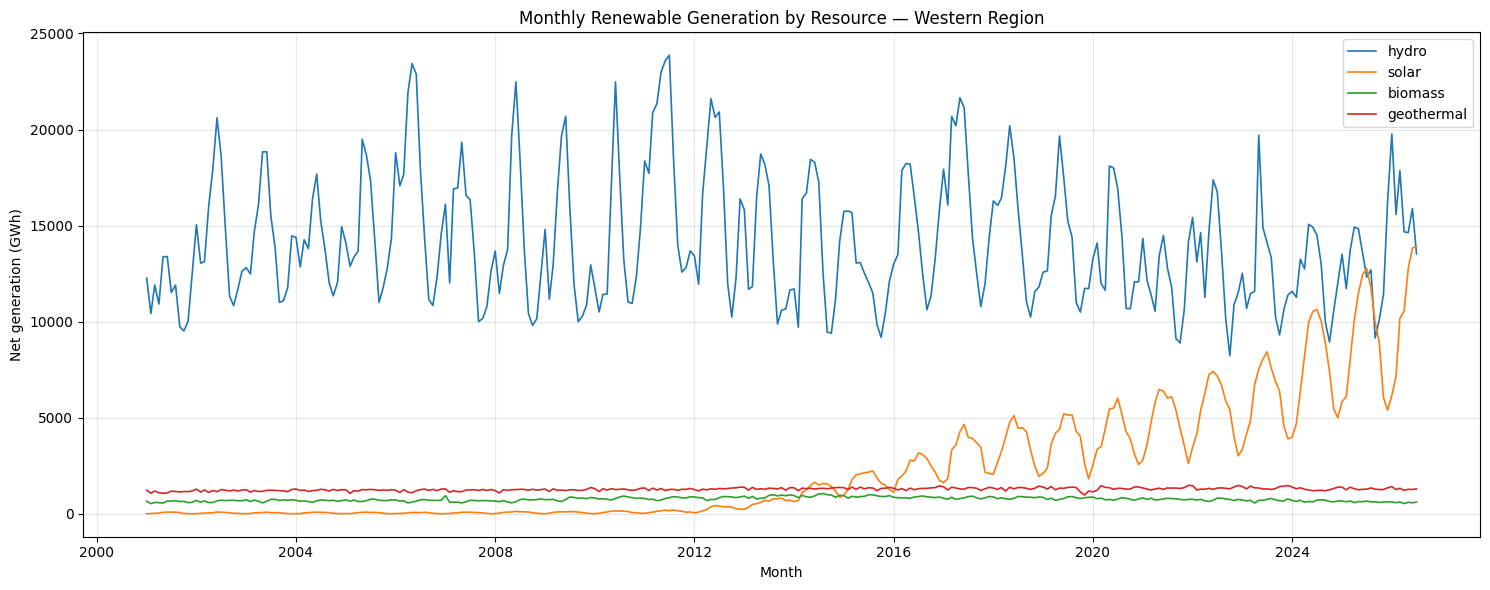

In [16]:
plt.figure(figsize=(15, 6))
for col in RESOURCES:
    plt.plot(west.index, west[col], linewidth=1.2, label=col)
plt.xlabel("Month")
plt.ylabel("Net generation (GWh)")
plt.title("Monthly Renewable Generation by Resource — Western Region")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

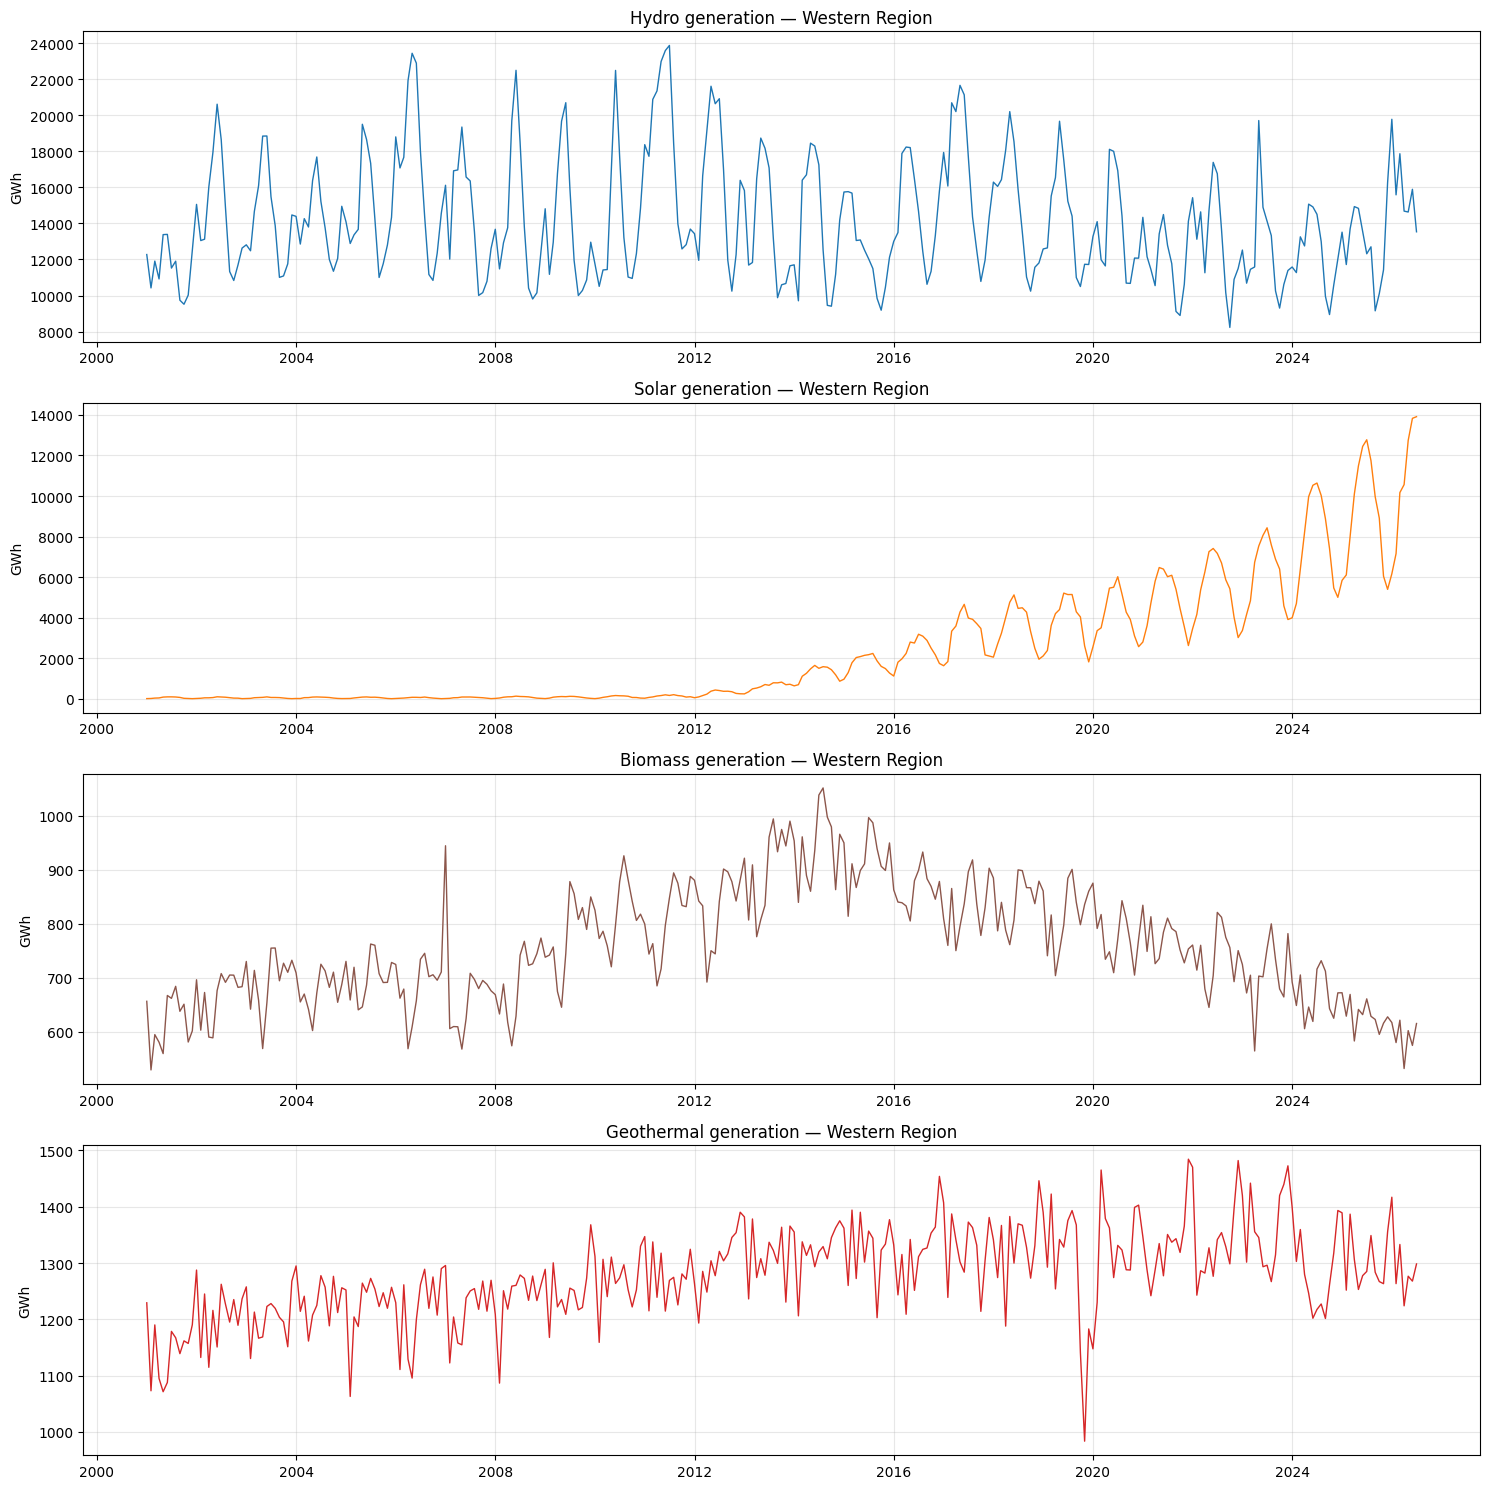

In [17]:
fig, axes = plt.subplots(4, 1, figsize=(15, 15))
colors = {"hydro": "tab:blue", "solar": "tab:orange", "biomass": "tab:brown", "geothermal": "tab:red"}
for ax, r in zip(axes, RESOURCES):
    ax.plot(series[r].index, series[r].values, color=colors[r], linewidth=1)
    ax.set_title(f"{r.capitalize()} generation — Western Region")
    ax.set_ylabel("GWh")
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [18]:
#@title Interpretation (generated from the results above)
def ym(ts): return f"{ts:%b %Y}"
yr_tot = {r: series[r].resample("YS").sum().loc[:"2025-01-01"] for r in RESOURCES}
for r in RESOURCES: yr_tot[r].index = yr_tot[r].index.year
h, s, b, g = (series[r] for r in RESOURCES)
wet, dry = yr_tot["hydro"].idxmax(), yr_tot["hydro"].idxmin()
b_roll = b.rolling(12).mean()
g_roll = g.rolling(12).mean()
g_dip = g.idxmin()
g_ref = g.loc[g_dip - pd.DateOffset(months=6): g_dip + pd.DateOffset(months=6)].median()
show(f"""**Initial visual observations**

1. **Hydro** is the largest and most variable resource, moving between about {h.min():,.0f} GWh ({ym(h.idxmin())}) and {h.max():,.0f} GWh ({ym(h.idxmax())}) per month.
   It has a strong yearly cycle, and its level changes a lot from year to year: the wettest complete year is {wet} ({yr_tot['hydro'][wet]:,.0f} GWh) and the driest is {dry} ({yr_tot['hydro'][dry]:,.0f} GWh).
   There is no obvious long-term direction.
2. **Solar** grows explosively. It averaged {s.iloc[:12].mean():,.0f} GWh per month in the first 12 months and {s.iloc[-12:].mean():,.0f} GWh in the last 12 months,
   with a record of {s.max():,.0f} GWh in {ym(s.idxmax())}. A yearly cycle repeats throughout, and **the size of the yearly swing grows with the level**
   (peak-to-trough range of {s.iloc[:12].max() - s.iloc[:12].min():,.0f} GWh in the first 12 months versus {s.iloc[-12:].max() - s.iloc[-12:].min():,.0f} GWh in the last 12).
3. **Biomass** is small and relatively stable, between {b.min():,.0f} and {b.max():,.0f} GWh per month. Its 12-month average peaked at {b_roll.max():,.0f} GWh in {ym(b_roll.idxmax())}
   and is now {b_roll.iloc[-1]:,.0f} GWh ({(b_roll.iloc[-1] / b_roll.max() - 1) * 100:+.0f}% from the peak). It shows a smaller, regular seasonal ripple.
4. **Geothermal** is the most stable of the four, between {g.min():,.0f} and {g.max():,.0f} GWh per month. Its 12-month average moved from {g_roll.dropna().iloc[0]:,.0f} to {g_roll.iloc[-1]:,.0f} GWh.
   Its lowest month, {ym(g_dip)} ({g.min():,.0f} GWh), is an isolated dip about {(1 - g.min() / g_ref) * 100:.0f}% below the surrounding months, which looks like an outage rather than a pattern.""")

**Initial visual observations**

1. **Hydro** is the largest and most variable resource, moving between about 8,231 GWh (Oct 2022) and 23,866 GWh (Jul 2011) per month.
   It has a strong yearly cycle, and its level changes a lot from year to year: the wettest complete year is 2011 (220,225 GWh) and the driest is 2001 (137,460 GWh).
   There is no obvious long-term direction.
2. **Solar** grows explosively. It averaged 45 GWh per month in the first 12 months and 9,717 GWh in the last 12 months,
   with a record of 13,914 GWh in Jul 2026. A yearly cycle repeats throughout, and **the size of the yearly swing grows with the level**
   (peak-to-trough range of 88 GWh in the first 12 months versus 8,518 GWh in the last 12).
3. **Biomass** is small and relatively stable, between 529 and 1,051 GWh per month. Its 12-month average peaked at 953 GWh in Oct 2014
   and is now 603 GWh (-37% from the peak). It shows a smaller, regular seasonal ripple.
4. **Geothermal** is the most stable of the four, between 984 and 1,484 GWh per month. Its 12-month average moved from 1,145 to 1,300 GWh.
   Its lowest month, Nov 2019 (984 GWh), is an isolated dip about 27% below the surrounding months, which looks like an outage rather than a pattern.

## 5. Trend Analysis

### 12-month rolling mean
A 12-month rolling mean removes the seasonal cycle and leaves the long-term movement.

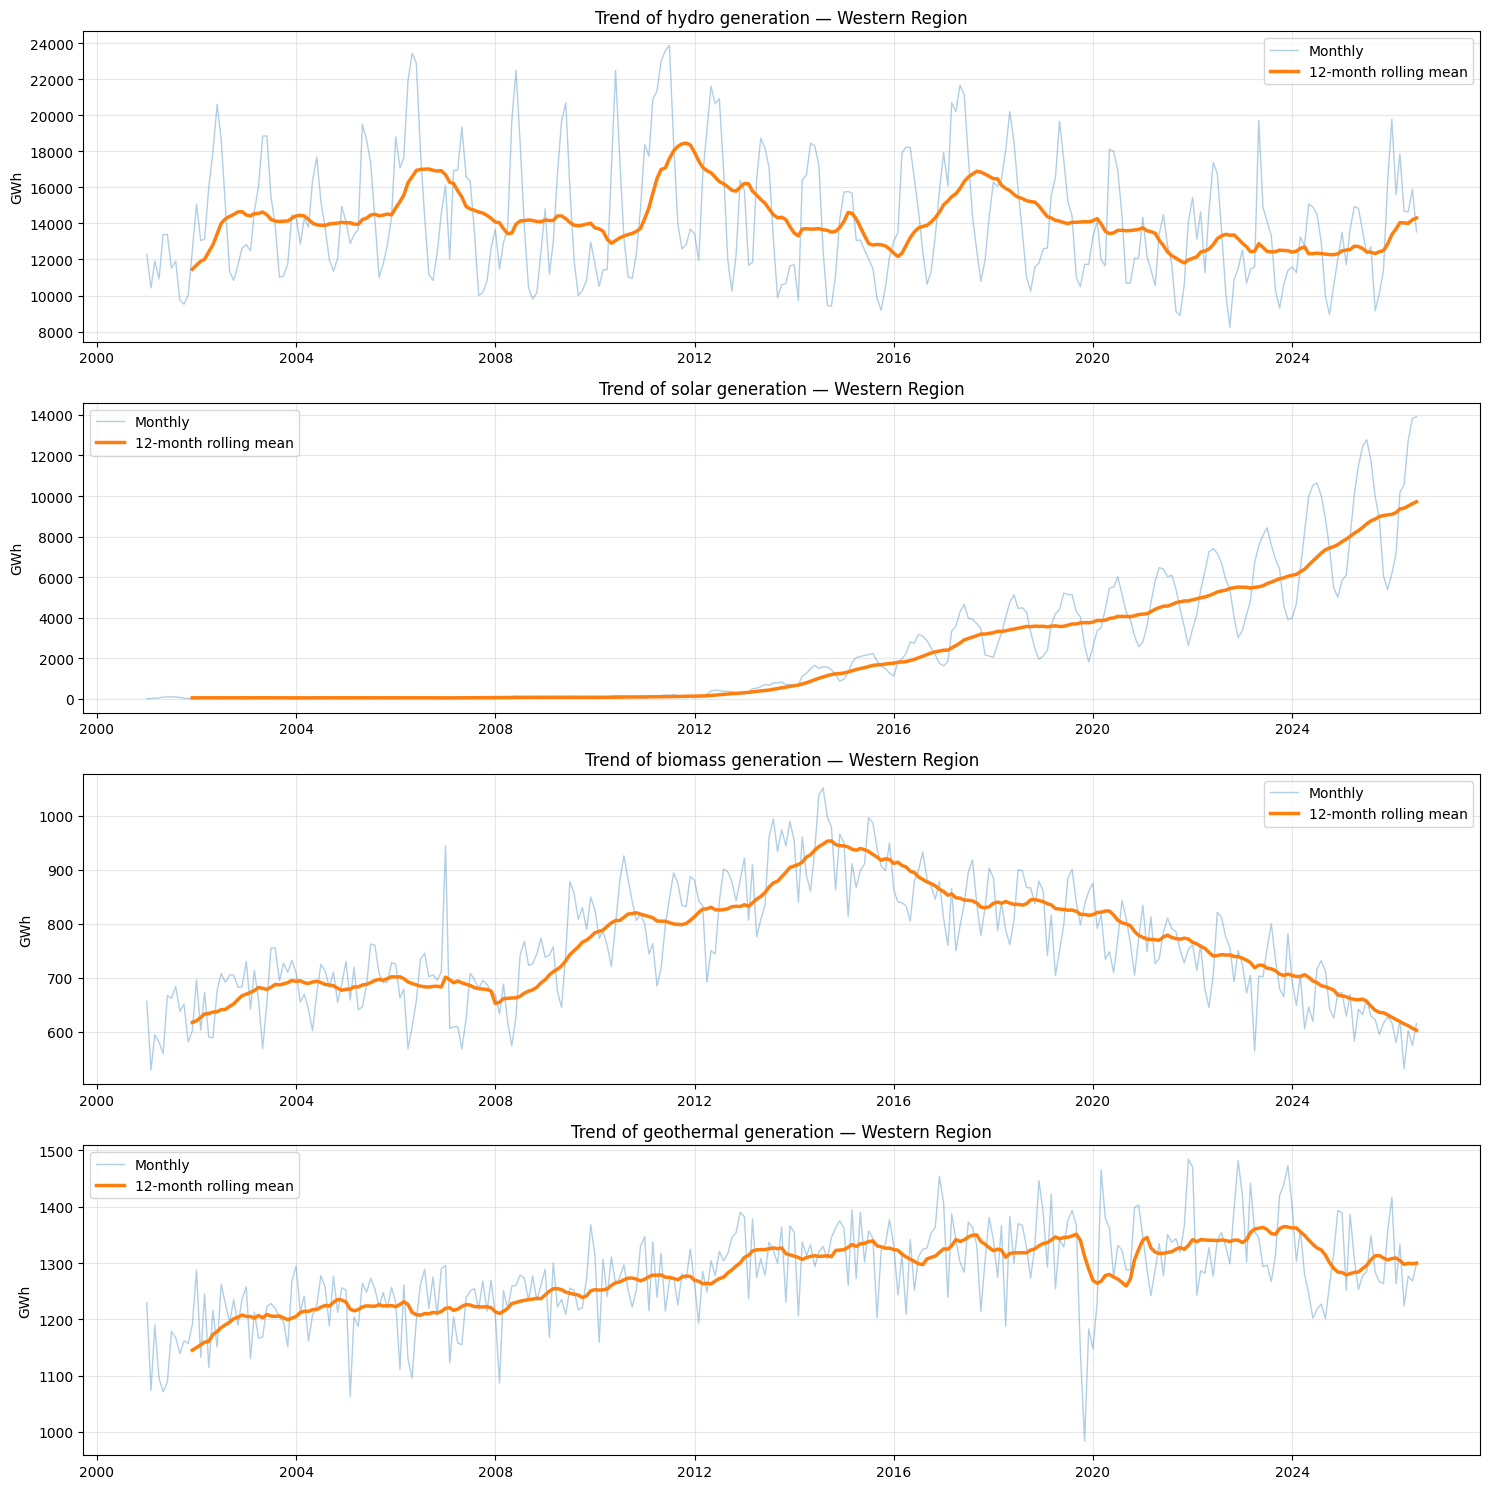

In [19]:
fig, axes = plt.subplots(4, 1, figsize=(15, 15))
for ax, r in zip(axes, RESOURCES):
    s = series[r]
    ax.plot(s.index, s, alpha=0.35, linewidth=1, label="Monthly")
    ax.plot(s.index, s.rolling(12).mean(), linewidth=2.5, label="12-month rolling mean")
    ax.set_title(f"Trend of {r} generation — Western Region")
    ax.set_ylabel("GWh")
    ax.legend()
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Annual totals and growth
Only complete calendar years are used (2026 is partial).

In [20]:
annual = pd.DataFrame({r: series[r].resample("YS").sum() for r in RESOURCES})
annual.index = annual.index.year
annual = annual.loc[:2025]

print("Annual generation (GWh):")
print(annual.round(0).to_string())

Annual generation (GWh):
           hydro      solar   biomass  geothermal
month                                            
2001  137460.000    543.000  7406.000   13741.000
2002  175801.000    555.000  8002.000   14491.000
2003  171386.000    534.000  8340.000   14424.000
2004  168672.000    575.000  8122.000   14811.000
2005  173630.000    550.000  8423.000   14692.000
2006  203052.000    508.000  8194.000   14568.000
2007  171381.000    612.000  8105.000   14648.000
2008  169079.000    860.000  8287.000   14840.000
2009  168077.000    863.000  9311.000   15009.000
2010  164628.000   1058.000  9811.000   15219.000
2011  220225.000   1500.000  9673.000   15316.000
2012  192144.000   3324.000  9980.000   15602.000
2013  165750.000   7350.000 10849.000   15775.000
2014  165251.000  14921.000 11332.000   15877.000
2015  150958.000  20906.000 11026.000   15918.000
2016  175444.000  28217.000 10366.000   15826.000
2017  199319.000  38646.000  9977.000   15927.000
2018  179588.000  42830.0

In [21]:
trend_rows = []
for r in RESOURCES:
    a = annual[r].dropna()
    slope, intercept = np.polyfit(a.index, a.values, 1)          # linear trend in GWh per year
    first, last = a.index.min(), a.index.max()
    cagr = (a.loc[last] / a.loc[first]) ** (1 / (last - first)) - 1
    cagr5 = (a.loc[last] / a.loc[last - 5]) ** (1 / 5) - 1       # growth over the last 5 complete years
    trend_rows.append({
        "resource": r,
        "years": f"{first}-{last}",
        "first_year_GWh": a.loc[first],
        "last_year_GWh": a.loc[last],
        "peak_year": a.idxmax(),
        "peak_year_GWh": a.max(),
        "linear_slope_GWh_per_year": slope,
        "CAGR_%": cagr * 100,
        "CAGR_last_5y_%": cagr5 * 100,
        "correlation_with_time": np.corrcoef(a.index, a.values)[0, 1],
    })
trend_summary = pd.DataFrame(trend_rows).set_index("resource")
trend_summary

,years,first_year_GWh,last_year_GWh,peak_year,peak_year_GWh,linear_slope_GWh_per_year,CAGR_%,CAGR_last_5y_%,correlation_with_time
resource,,,,,,,,,
hydro,2001-2025,137460.063,154215.052,2011,220224.511,-695.006,0.480,-1.216,-0.269
solar,2001-2025,542.760,108827.428,2025,108827.428,3976.112,24.716,16.905,0.901
biomass,2001-2025,7406.009,7577.655,2014,11331.686,40.524,0.096,-4.094,0.268
geothermal,2001-2025,13740.501,15667.651,2023,16367.398,77.839,0.548,-0.281,0.863


In [22]:
#@title Interpretation (generated from the results above)
annual_ac = {r: annual[r].autocorr(1) for r in RESOURCES}

def trend_label(r):
    t = trend_summary.loc[r]
    corr, cg, last, peak = t["correlation_with_time"], t["CAGR_%"], t["last_year_GWh"], t["peak_year_GWh"]
    if cg > 10 and corr > 0.7:
        return "Strong, exponential-type growth"
    if corr > 0.7 and cg > 0:
        return "Slow upward drift" + (" that has levelled off" if last < 0.97 * peak else "")
    if abs(corr) < 0.6 and annual_ac[r] > 0.7:
        return "Rise and decline (hump-shaped)"
    if abs(corr) < 0.6:
        return "No meaningful trend (year-to-year swings)"
    return "Downward drift" if corr < 0 else "Upward drift"

rows_md = []
for r in RESOURCES:
    t = trend_summary.loc[r]
    inc_last = annual[r].iloc[-1] - annual[r].iloc[-2]
    inc_prev = annual[r].iloc[-2] - annual[r].iloc[-3]
    txt = (f"Annual output went from {t['first_year_GWh']:,.0f} GWh ({annual.index.min()}) to {t['last_year_GWh']:,.0f} GWh ({annual.index.max()}), "
           f"a compound growth rate of {t['CAGR_%']:.1f}%/yr ({t['CAGR_last_5y_%']:+.1f}%/yr over the last 5 years). "
           f"The peak was {t['peak_year_GWh']:,.0f} GWh in {int(t['peak_year'])}. "
           f"Linear slope {t['linear_slope_GWh_per_year']:+,.0f} GWh/yr, correlation with time {t['correlation_with_time']:.2f}. ")
    if r == "solar":
        trend_word = ("so the yearly additions are still rising" if inc_last > 1.05 * inc_prev else
                      "so the yearly additions are slowing" if inc_last < 0.95 * inc_prev else "so the yearly additions are holding roughly steady")
        txt += (f"The latest complete year added {inc_last:+,.0f} GWh (previous year {inc_prev:+,.0f} GWh), {trend_word}; "
                f"the percentage growth rate is lower than the long-run average ({t['CAGR_last_5y_%']:.0f}%/yr over the last 5 years versus {t['CAGR_%']:.0f}%/yr overall).")
    elif r == "hydro":
        txt += f"Annual values swing between {annual[r].min():,.0f} and {annual[r].max():,.0f} GWh, so wet and dry years, not a trend, drive the changes."
    else:
        txt += f"The latest complete year is {(t['last_year_GWh'] / t['peak_year_GWh'] - 1) * 100:+.0f}% relative to the peak year."
    rows_md.append(f"| {r.capitalize()} | **{trend_label(r)}.** {txt} |")
table = "\n".join(rows_md)
labels = "; ".join(f"{r} = {trend_label(r).lower()}" for r in RESOURCES)
show(f"""**Trend interpretation**

| Resource | Long-term behaviour |
|---|---|
{table}

**Key finding:** the four resources follow different long-term paths ({labels}). A straight-line trend is
misleading for the hump-shaped and levelled-off series, so each resource needs its own model.""")

**Trend interpretation**

| Resource | Long-term behaviour |
|---|---|
| Hydro | **No meaningful trend (year-to-year swings).** Annual output went from 137,460 GWh (2001) to 154,215 GWh (2025), a compound growth rate of 0.5%/yr (-1.2%/yr over the last 5 years). The peak was 220,225 GWh in 2011. Linear slope -695 GWh/yr, correlation with time -0.27. Annual values swing between 137,460 and 220,225 GWh, so wet and dry years, not a trend, drive the changes. |
| Solar | **Strong, exponential-type growth.** Annual output went from 543 GWh (2001) to 108,827 GWh (2025), a compound growth rate of 24.7%/yr (+16.9%/yr over the last 5 years). The peak was 108,827 GWh in 2025. Linear slope +3,976 GWh/yr, correlation with time 0.90. The latest complete year added +17,630 GWh (previous year +18,719 GWh), so the yearly additions are slowing; the percentage growth rate is lower than the long-run average (17%/yr over the last 5 years versus 25%/yr overall). |
| Biomass | **Rise and decline (hump-shaped).** Annual output went from 7,406 GWh (2001) to 7,578 GWh (2025), a compound growth rate of 0.1%/yr (-4.1%/yr over the last 5 years). The peak was 11,332 GWh in 2014. Linear slope +41 GWh/yr, correlation with time 0.27. The latest complete year is -33% relative to the peak year. |
| Geothermal | **Slow upward drift that has levelled off.** Annual output went from 13,741 GWh (2001) to 15,668 GWh (2025), a compound growth rate of 0.5%/yr (-0.3%/yr over the last 5 years). The peak was 16,367 GWh in 2023. Linear slope +78 GWh/yr, correlation with time 0.86. The latest complete year is -4% relative to the peak year. |

**Key finding:** the four resources follow different long-term paths (hydro = no meaningful trend (year-to-year swings); solar = strong, exponential-type growth; biomass = rise and decline (hump-shaped); geothermal = slow upward drift that has levelled off). A straight-line trend is
misleading for the hump-shaped and levelled-off series, so each resource needs its own model.

### Does the variability grow with the level?
If the seasonal swings get larger as the level rises, the seasonality is **multiplicative**, and a log transform (or a multiplicative model) is needed.

In [23]:
for r in RESOURCES:
    s = series[r]
    roll_mean = s.rolling(12).mean()
    roll_std = s.rolling(12).std()
    corr = roll_mean.corr(roll_std)
    print(f"{r:10s}: correlation between 12-month rolling mean and rolling std = {corr:.3f}")

hydro     : correlation between 12-month rolling mean and rolling std = 0.749
solar     : correlation between 12-month rolling mean and rolling std = 0.993
biomass   : correlation between 12-month rolling mean and rolling std = 0.326
geothermal: correlation between 12-month rolling mean and rolling std = 0.184


In [24]:
#@title Interpretation (generated from the results above)
corrs = {r: series[r].rolling(12).mean().corr(series[r].rolling(12).std()) for r in RESOURCES}
def mult_label(c):
    return "swings grow with the level (multiplicative behaviour)" if c > 0.7 else ("moderate link between level and swings" if c > 0.4 else "swings do not grow with the level (additive behaviour)")
lines = "\n".join(f"* **{r.capitalize()}**: correlation {corrs[r]:.2f}, {mult_label(corrs[r])}." for r in RESOURCES)
extra = ""
for r in RESOURCES:
    if r != "solar" and corrs[r] > 0.5:
        extra += (f"\n* **Caution for {r}:** the correlation is {corrs[r]:.2f}, but its level has no growth trend. High-level periods are wet years in which the whole seasonal peak is larger, "
                  "so the link comes from year-to-year weather and not from structural growth. The notebook still decomposes it additively, and this is a simplification.")
show(f"""**Additive or multiplicative?**

{lines}

* **Decision:** solar is treated as multiplicative (decomposition = multiplicative, log transform for modelling). The other resources are treated as additive.{extra}""")

**Additive or multiplicative?**

* **Hydro**: correlation 0.75, swings grow with the level (multiplicative behaviour).
* **Solar**: correlation 0.99, swings grow with the level (multiplicative behaviour).
* **Biomass**: correlation 0.33, swings do not grow with the level (additive behaviour).
* **Geothermal**: correlation 0.18, swings do not grow with the level (additive behaviour).

* **Decision:** solar is treated as multiplicative (decomposition = multiplicative, log transform for modelling). The other resources are treated as additive.
* **Caution for hydro:** the correlation is 0.75, but its level has no growth trend. High-level periods are wet years in which the whole seasonal peak is larger, so the link comes from year-to-year weather and not from structural growth. The notebook still decomposes it additively, and this is a simplification.

## 6. Seasonality Analysis

### Seasonal plot: one line per year

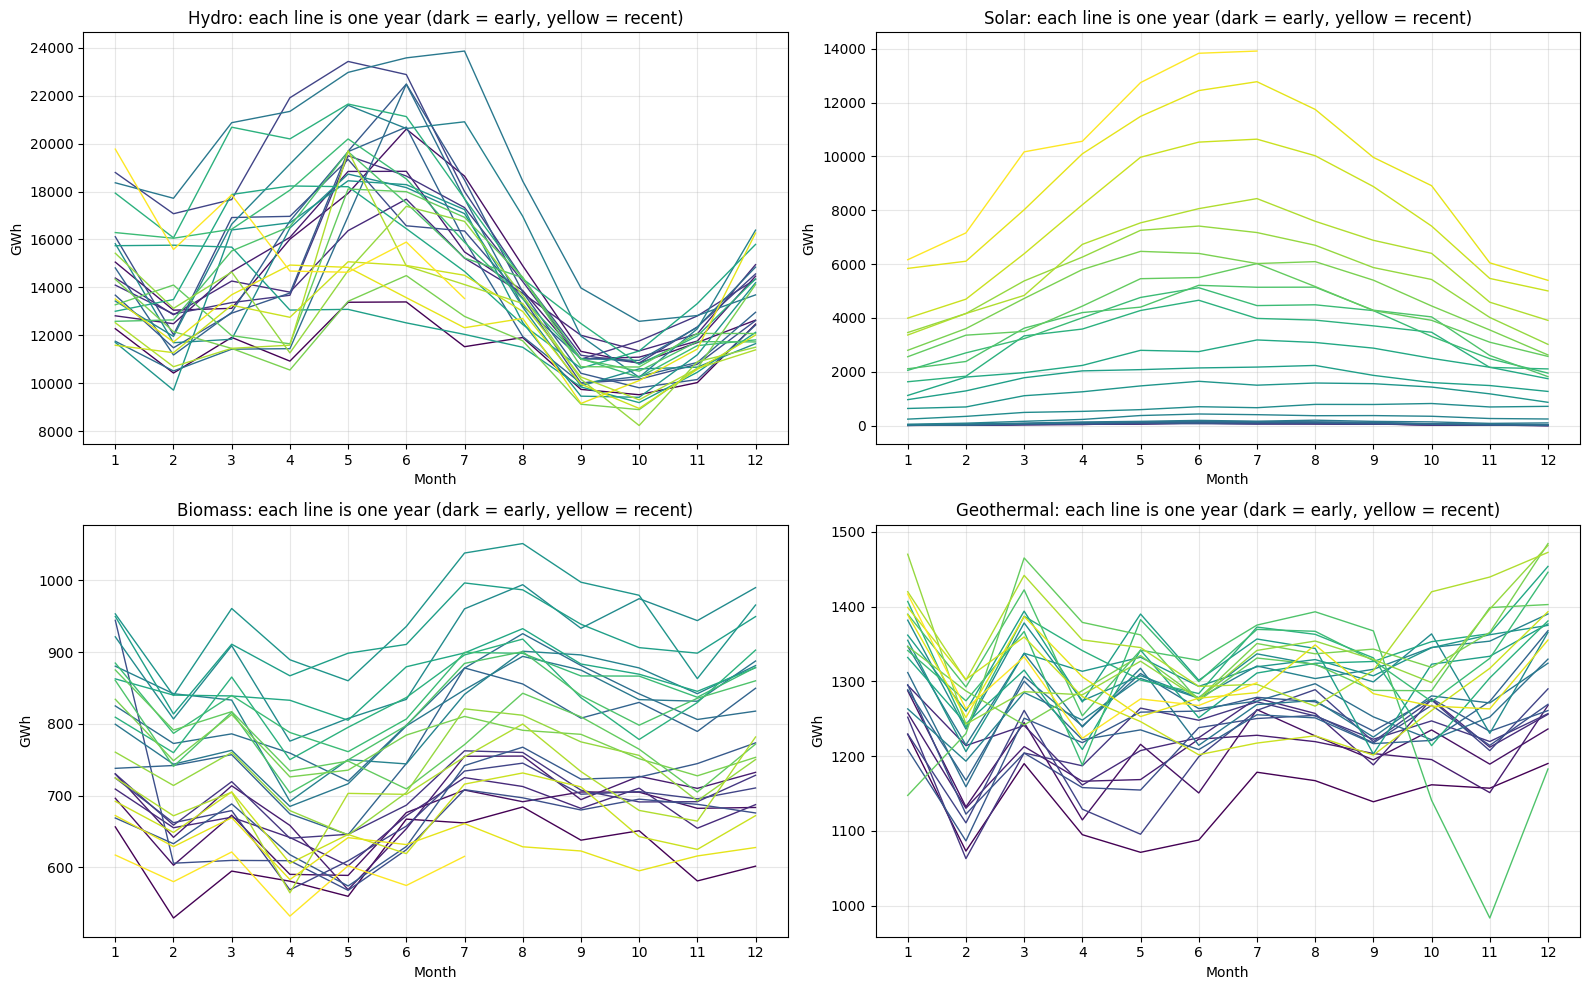

In [25]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
for ax, r in zip(axes.ravel(), RESOURCES):
    s = series[r]
    for year in sorted(set(s.index.year)):
        part = s[s.index.year == year]
        ax.plot(part.index.month, part.values, linewidth=1,
                color=plt.cm.viridis((year - s.index.year.min()) / (s.index.year.max() - s.index.year.min())))
    ax.set_xticks(range(1, 13))
    ax.set_xlabel("Month")
    ax.set_ylabel("GWh")
    ax.set_title(f"{r.capitalize()}: each line is one year (dark = early, yellow = recent)")
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Average monthly profile
To remove the trend first, each month is divided by its own 12-month centred moving average. A value of 1.10 means 10% above the trend level.

       hydro  solar  biomass  geothermal
month                                   
1      1.032  0.447    1.045       1.036
2      0.921  0.607    0.943       0.943
3      1.039  0.960    1.004       1.028
4      1.085  1.164    0.902       0.969
5      1.293  1.397    0.910       1.000
6      1.289  1.536    0.967       0.979
7      1.148  1.451    1.068       1.014
8      0.968  1.413    1.084       1.013
9      0.756  1.192    1.034       0.987
10     0.728  0.890    1.015       0.996
11     0.811  0.597    0.986       0.994
12     0.946  0.418    1.038       1.049


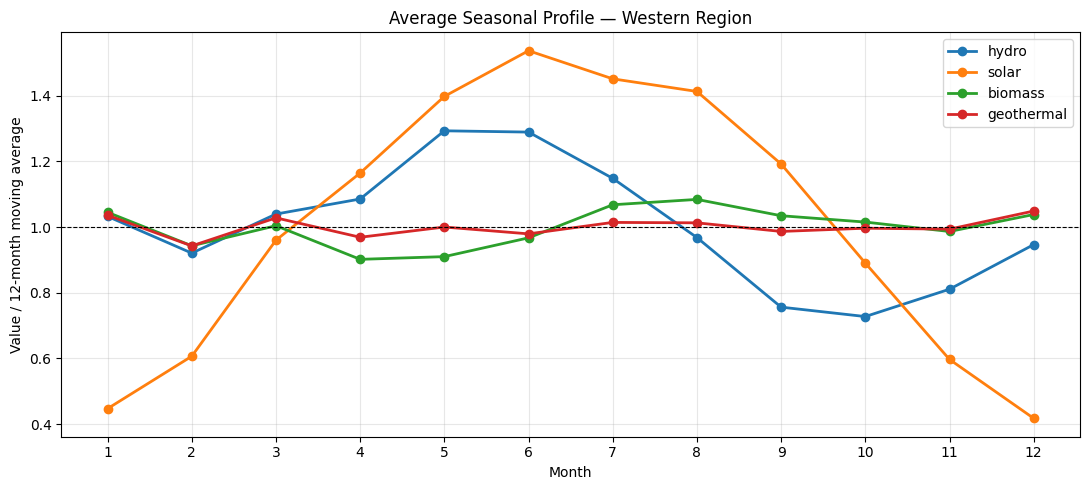

hydro     : peak month =  5 (+29.3%), trough month = 10 (-27.2%)
solar     : peak month =  6 (+53.6%), trough month = 12 (-58.2%)
biomass   : peak month =  8 (+8.4%), trough month =  4 (-9.8%)
geothermal: peak month = 12 (+4.9%), trough month =  2 (-5.7%)


In [26]:
seasonal_index = {}
for r in RESOURCES:
    s = series[r]
    centred_ma = s.rolling(12, center=True).mean()
    ratio = (s / centred_ma).dropna()
    seasonal_index[r] = ratio.groupby(ratio.index.month).mean()

seasonal_index = pd.DataFrame(seasonal_index)
seasonal_index.index.name = "month"
print(seasonal_index.round(3).to_string())

plt.figure(figsize=(11, 5))
for r in RESOURCES:
    plt.plot(seasonal_index.index, seasonal_index[r], marker="o", linewidth=2, label=r)
plt.axhline(1, color="black", linewidth=0.8, linestyle="--")
plt.xticks(range(1, 13))
plt.xlabel("Month")
plt.ylabel("Value / 12-month moving average")
plt.title("Average Seasonal Profile — Western Region")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

for r in RESOURCES:
    print(f"{r:10s}: peak month = {seasonal_index[r].idxmax():2d} ({(seasonal_index[r].max()-1)*100:+.1f}%), "
          f"trough month = {seasonal_index[r].idxmin():2d} ({(seasonal_index[r].min()-1)*100:+.1f}%)")

In [27]:
#@title Interpretation (generated from the results above)
def season_name(m): return {12: "winter", 1: "winter", 2: "winter", 3: "spring", 4: "spring", 5: "spring", 6: "summer", 7: "summer", 8: "summer"}.get(m, "autumn")
EXPL = {
    "hydro": "consistent with snowmelt and spring runoff in the Pacific Northwest and the Rockies, followed by the dry late-summer and autumn season" ,
    "solar": "follows the length of the day and the sun's height: most output in summer, least in winter",
    "biomass": "a small ripple, which can reflect fuel supply and the seasonal demand for electricity",
    "geothermal": "a very small cycle, because geothermal plants run almost continuously; the small differences can reflect plant efficiency and maintenance schedules",
}
rows_md = []
for r in RESOURCES:
    pk, tr = int(seasonal_index[r].idxmax()), int(seasonal_index[r].idxmin())
    rows_md.append(f"| {r.capitalize()} | {MONTH_NAME[pk]} ({(seasonal_index[r].max() - 1) * 100:+.1f}%) | {MONTH_NAME[tr]} ({(seasonal_index[r].min() - 1) * 100:+.1f}%) "
                   f"| {seasonal_index[r].max() / seasonal_index[r].min():.2f}x | {EXPL[r]} |")
table = "\n".join(rows_md)
c_hs = seasonal_index["hydro"].corr(seasonal_index["solar"])
if c_hs > 0.4:
    cross = (f"Hydro and solar have **similar** seasonal profiles (correlation {c_hs:.2f}): both are high in spring and summer and low in autumn and winter, so they do not offset each other through the year.")
elif c_hs < -0.4:
    cross = f"Hydro and solar have **opposite** seasonal profiles (correlation {c_hs:.2f}), so together they smooth the regional supply across the year."
else:
    cross = f"Hydro and solar have only a weak seasonal relationship (correlation {c_hs:.2f})."
show(f"""**Seasonal pattern** (value divided by its 12-month centred average, averaged over all years)

| Resource | Peak month | Trough month | Peak / trough | Likely explanation |
|---|---|---|---|---|
{table}

* The strongest seasonal swings are in **{max(RESOURCES, key=lambda r: seasonal_index[r].max() / seasonal_index[r].min())}**, and the weakest in **{min(RESOURCES, key=lambda r: seasonal_index[r].max() / seasonal_index[r].min())}**.
* {cross}
* Peak seasons: hydro in {season_name(int(seasonal_index['hydro'].idxmax()))}, solar in {season_name(int(seasonal_index['solar'].idxmax()))}, biomass in {season_name(int(seasonal_index['biomass'].idxmax()))}, geothermal in {season_name(int(seasonal_index['geothermal'].idxmax()))}.""")

**Seasonal pattern** (value divided by its 12-month centred average, averaged over all years)

| Resource | Peak month | Trough month | Peak / trough | Likely explanation |
|---|---|---|---|---|
| Hydro | May (+29.3%) | Oct (-27.2%) | 1.78x | consistent with snowmelt and spring runoff in the Pacific Northwest and the Rockies, followed by the dry late-summer and autumn season |
| Solar | Jun (+53.6%) | Dec (-58.2%) | 3.68x | follows the length of the day and the sun's height: most output in summer, least in winter |
| Biomass | Aug (+8.4%) | Apr (-9.8%) | 1.20x | a small ripple, which can reflect fuel supply and the seasonal demand for electricity |
| Geothermal | Dec (+4.9%) | Feb (-5.7%) | 1.11x | a very small cycle, because geothermal plants run almost continuously; the small differences can reflect plant efficiency and maintenance schedules |

* The strongest seasonal swings are in **solar**, and the weakest in **geothermal**.
* Hydro and solar have **similar** seasonal profiles (correlation 0.52): both are high in spring and summer and low in autumn and winter, so they do not offset each other through the year.
* Peak seasons: hydro in spring, solar in summer, biomass in summer, geothermal in winter.

### Month-of-year boxplots

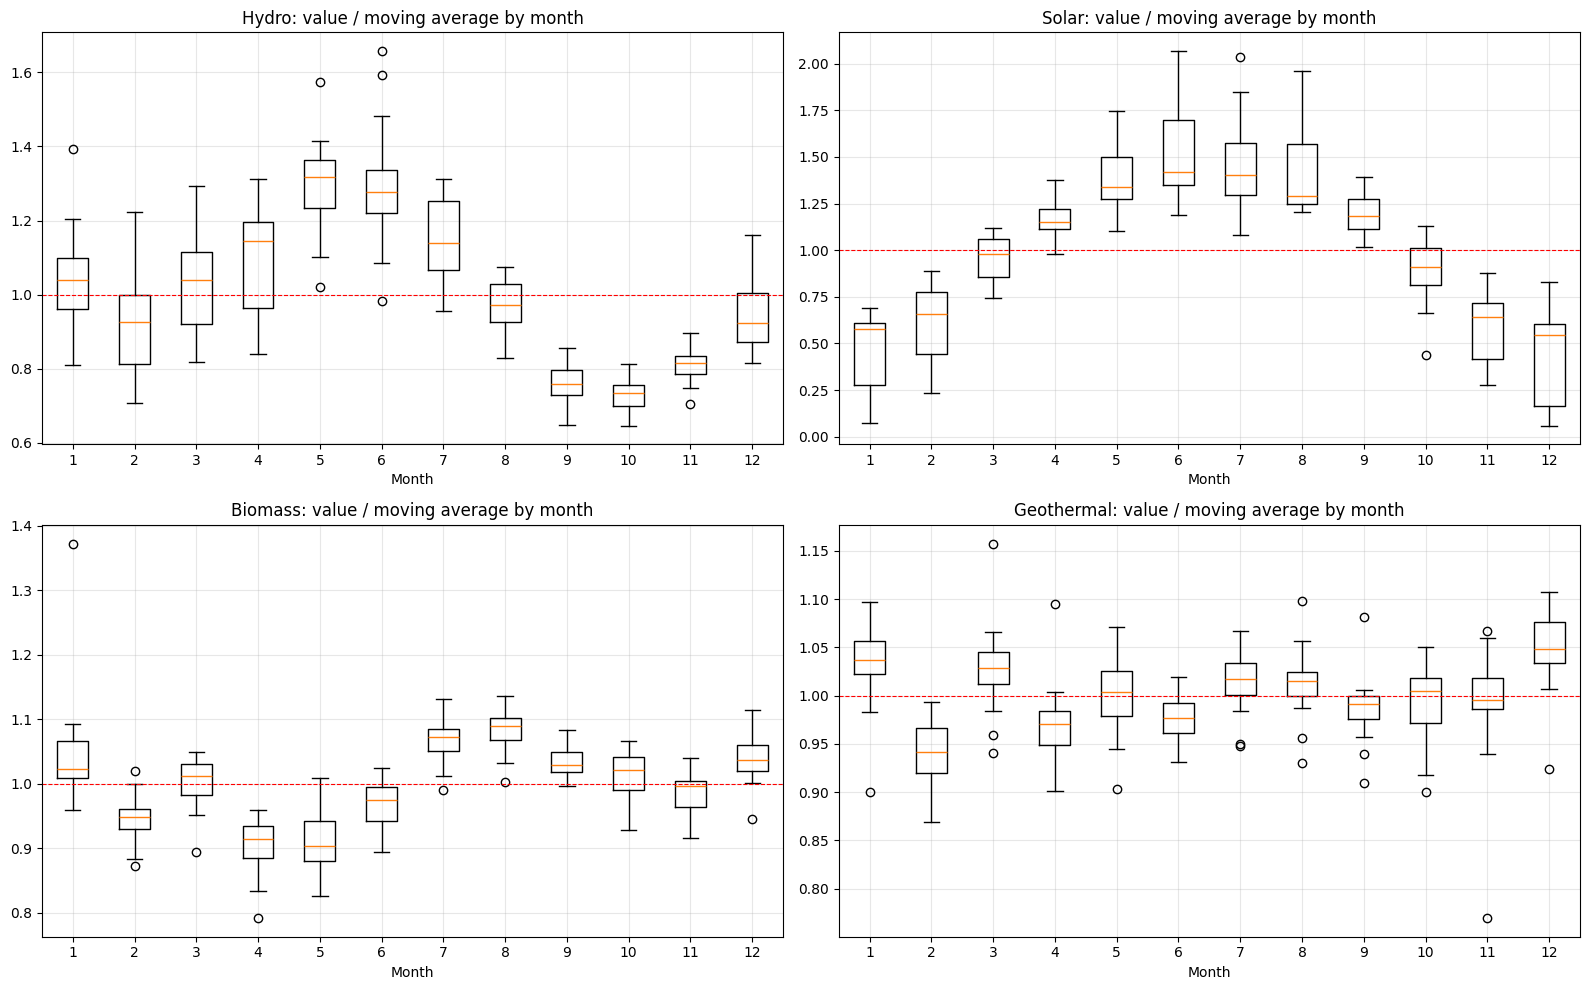

In [28]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
for ax, r in zip(axes.ravel(), RESOURCES):
    s = series[r]
    ratio = (s / s.rolling(12, center=True).mean()).dropna()
    data = [ratio[ratio.index.month == m].values for m in range(1, 13)]
    ax.boxplot(data, tick_labels=range(1, 13))
    ax.axhline(1, color="red", linestyle="--", linewidth=0.8)
    ax.set_title(f"{r.capitalize()}: value / moving average by month")
    ax.set_xlabel("Month")
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Seasonal decomposition (period = 12 months)
An **additive** model is used for resources whose variability does not grow with the level, and a **multiplicative** model for solar,
based on the variance check above.

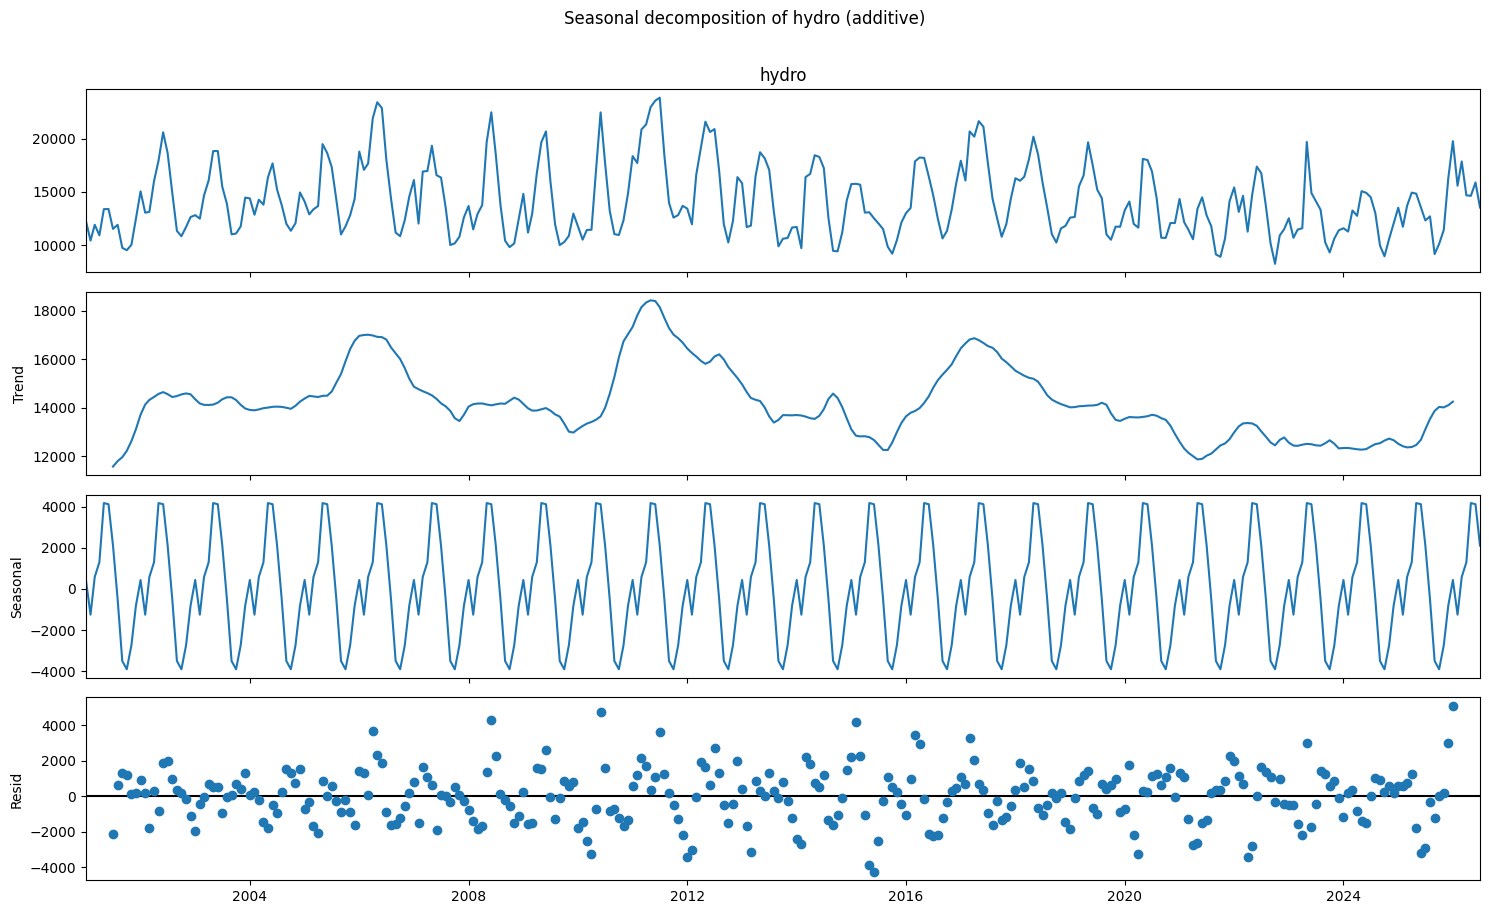

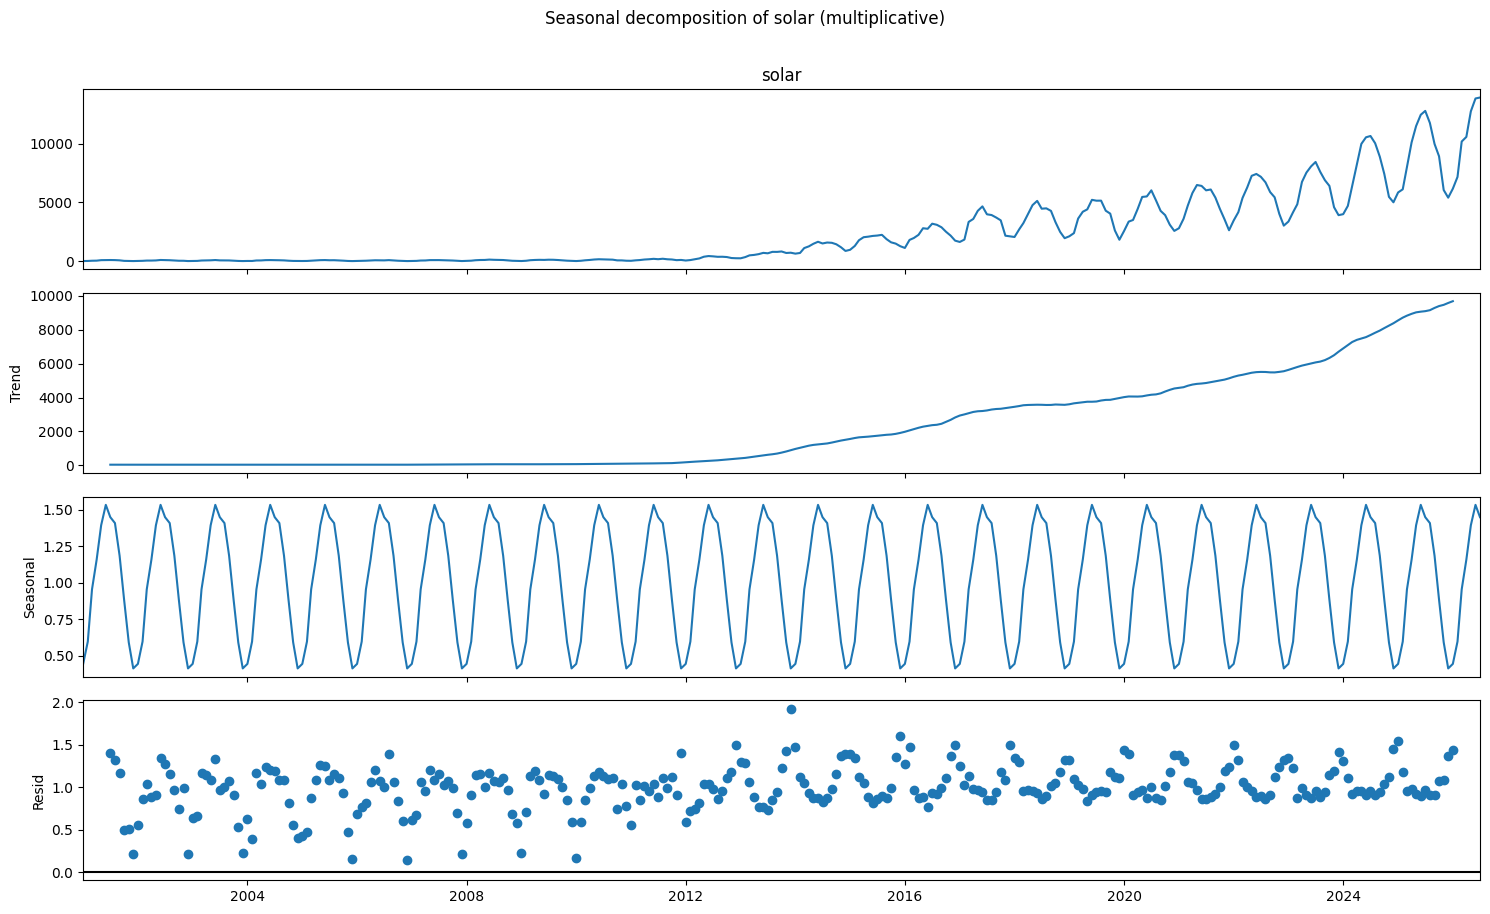

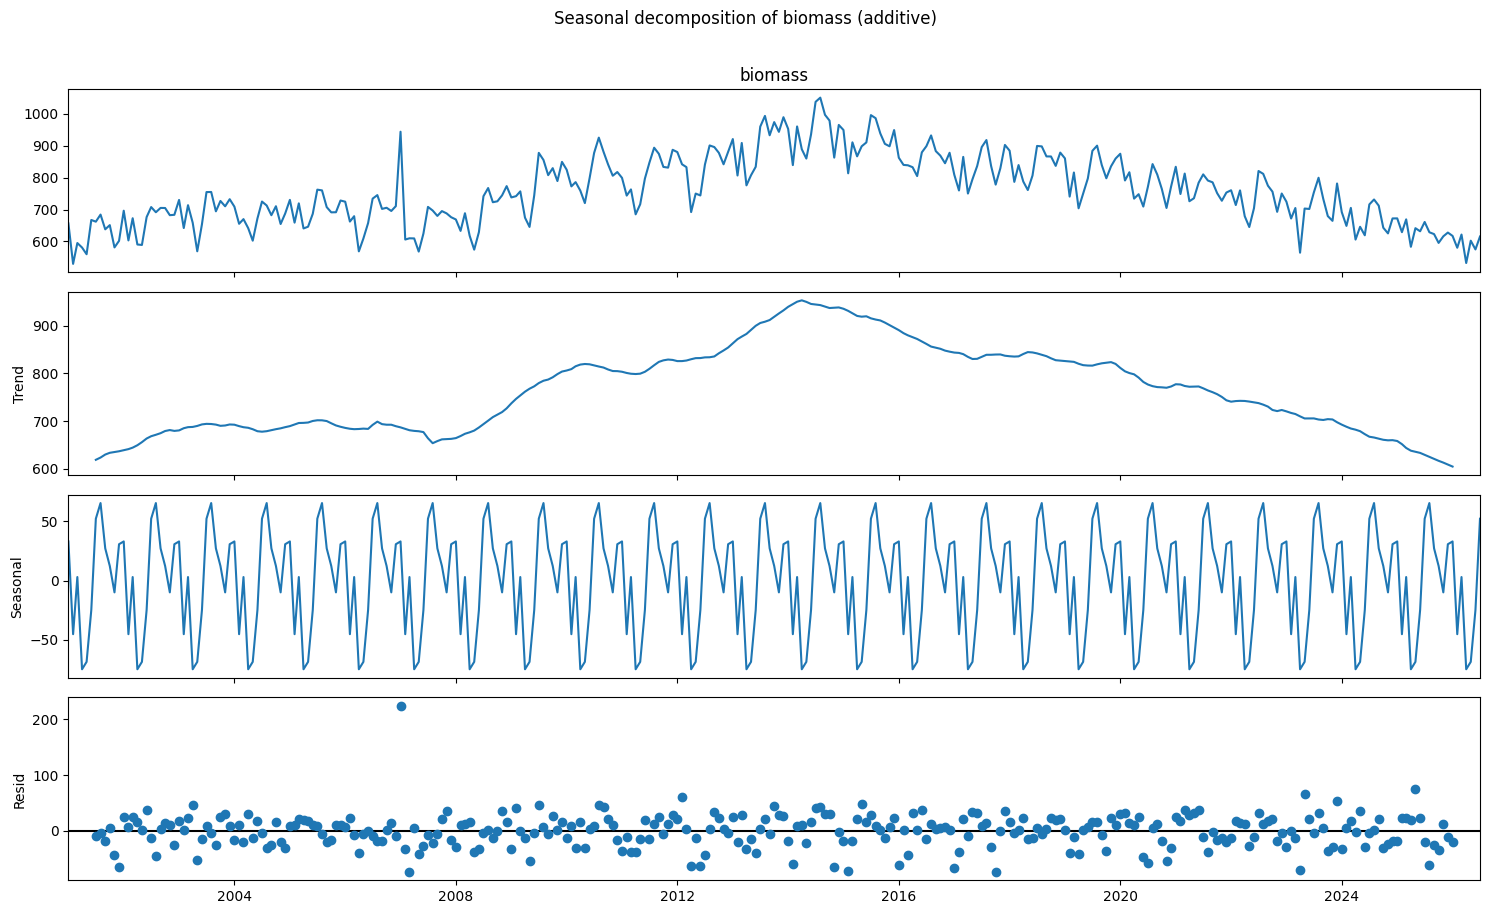

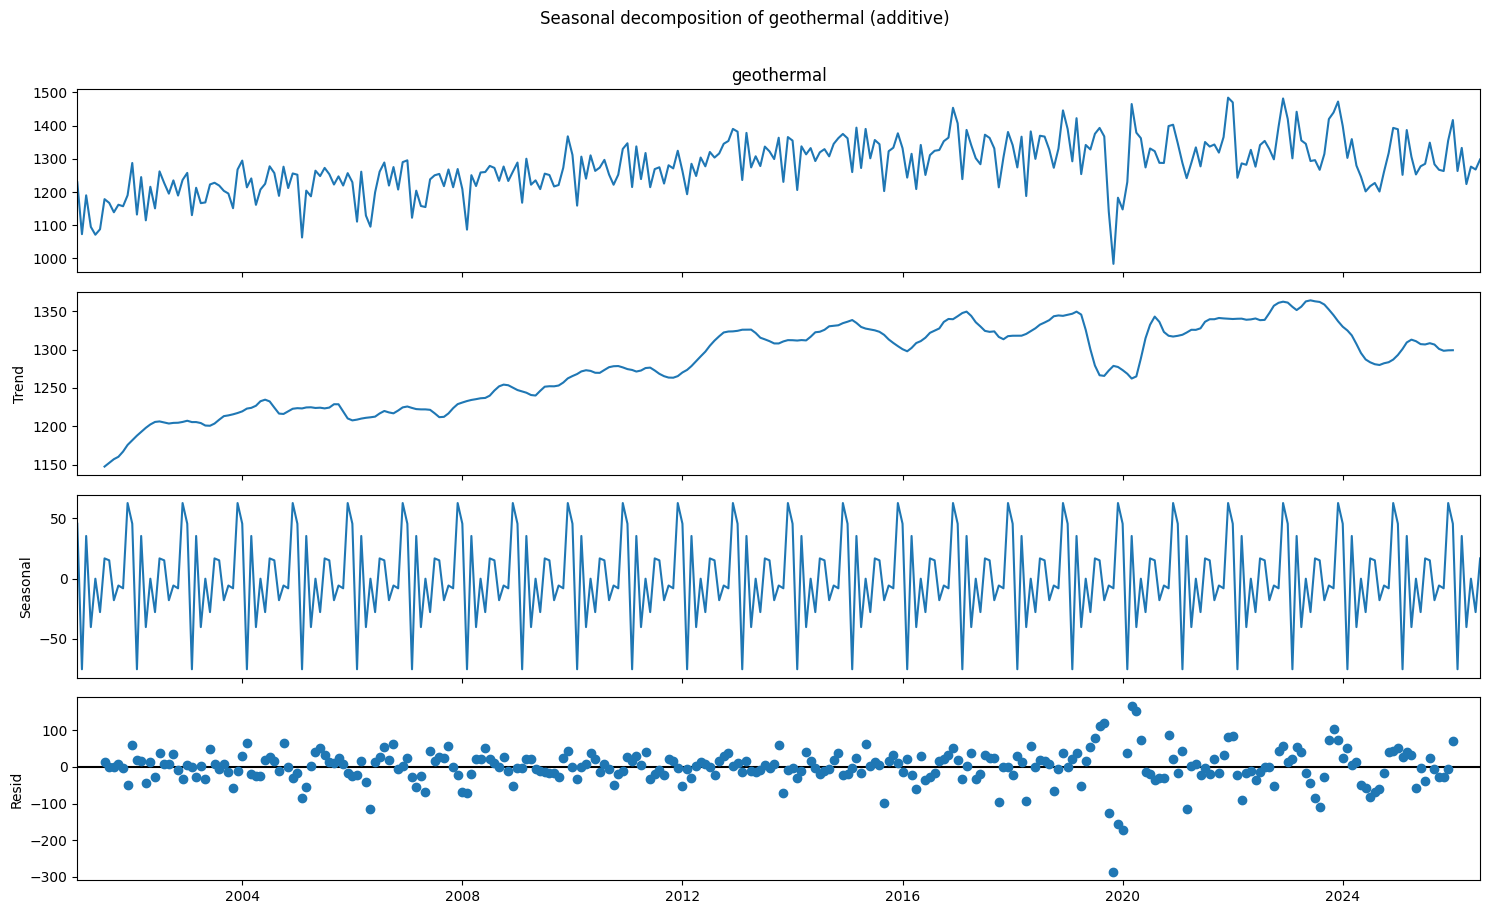

In [29]:
decomp_model = {"hydro": "additive", "solar": "multiplicative", "biomass": "additive", "geothermal": "additive"}
decomposition = {}

for r in RESOURCES:
    decomposition[r] = seasonal_decompose(series[r], model=decomp_model[r], period=12)
    fig = decomposition[r].plot()
    fig.set_size_inches(15, 9)
    fig.suptitle(f"Seasonal decomposition of {r} ({decomp_model[r]})", y=1.01)
    plt.tight_layout()
    plt.show()

In [30]:
# Seasonal strength (0 = no seasonality, 1 = only seasonality) = 1 - Var(residual) / Var(seasonal + residual)
strength_rows = []
for r in RESOURCES:
    d = decomposition[r]
    if decomp_model[r] == "multiplicative":       # work on the log scale so the parts add up
        seas, resid, trend = np.log(d.seasonal), np.log(d.resid), np.log(d.trend)
    else:
        seas, resid, trend = d.seasonal, d.resid, d.trend
    seas, resid, trend = seas[resid.notna()], resid.dropna(), trend.dropna()
    strength_rows.append({
        "resource": r,
        "seasonal_strength": max(0, 1 - resid.var() / (seas + resid).var()),
        "trend_strength": max(0, 1 - resid.var() / (trend + resid).var()),
    })
strength = pd.DataFrame(strength_rows).set_index("resource")
strength

,seasonal_strength,trend_strength
resource,,
hydro,0.740,0.516
solar,0.671,0.973
biomass,0.676,0.901
geothermal,0.387,0.559


In [31]:
#@title Interpretation (generated from the results above)
def strength_word(x): return "strong" if x > 0.64 else ("moderate" if x > 0.3 else "weak")
rows_md = []
for r in RESOURCES:
    ss, ts = strength.loc[r, "seasonal_strength"], strength.loc[r, "trend_strength"]
    rows_md.append(f"| {r.capitalize()} | {decomp_model[r]} | {ss:.2f} ({strength_word(ss)}) | {ts:.2f} ({strength_word(ts)}) |")
table = "\n".join(rows_md)
most = strength["seasonal_strength"].idxmax(); least = strength["seasonal_strength"].idxmin()
show(f"""**Seasonal decomposition interpretation**

| Resource | Model | Seasonal strength | Trend strength |
|---|---|---|---|
{table}

* Seasonality is strongest for **{most}** ({strength.loc[most, 'seasonal_strength']:.2f}) and weakest for **{least}** ({strength.loc[least, 'seasonal_strength']:.2f}).
* Strength is measured as 1 − Var(residual) / Var(component + residual): 0 means the component is invisible, 1 means it explains everything. Values above about 0.64 are treated as strong in the differencing rule of Section 7.3.
* For solar, strength is computed on the log scale, so the parts add up.""")

**Seasonal decomposition interpretation**

| Resource | Model | Seasonal strength | Trend strength |
|---|---|---|---|
| Hydro | additive | 0.74 (strong) | 0.52 (moderate) |
| Solar | multiplicative | 0.67 (strong) | 0.97 (strong) |
| Biomass | additive | 0.68 (strong) | 0.90 (strong) |
| Geothermal | additive | 0.39 (moderate) | 0.56 (moderate) |

* Seasonality is strongest for **hydro** (0.74) and weakest for **geothermal** (0.39).
* Strength is measured as 1 − Var(residual) / Var(component + residual): 0 means the component is invisible, 1 means it explains everything. Values above about 0.64 are treated as strong in the differencing rule of Section 7.3.
* For solar, strength is computed on the log scale, so the parts add up.

### ACF of the original series
For monthly data, repeated peaks at lags 12, 24, 36 indicate a **yearly seasonal cycle**.

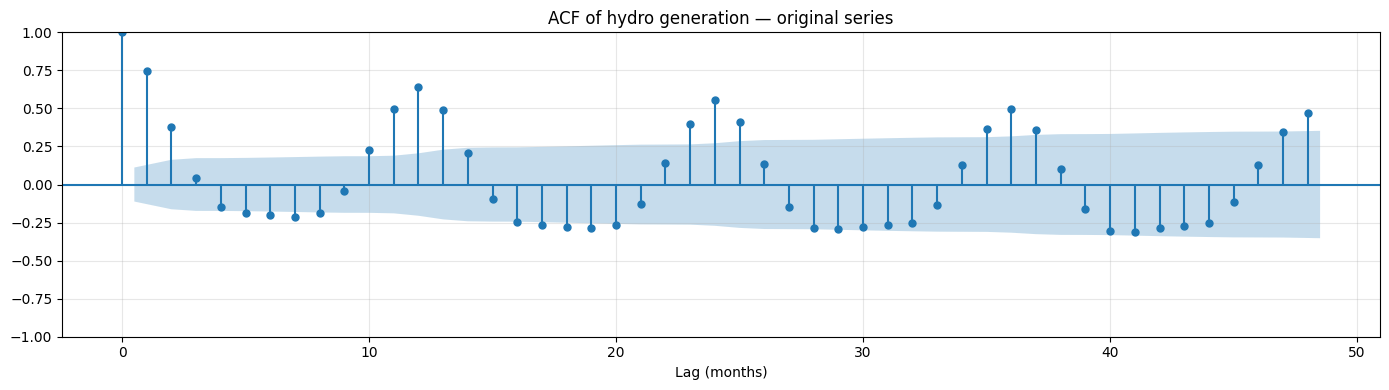

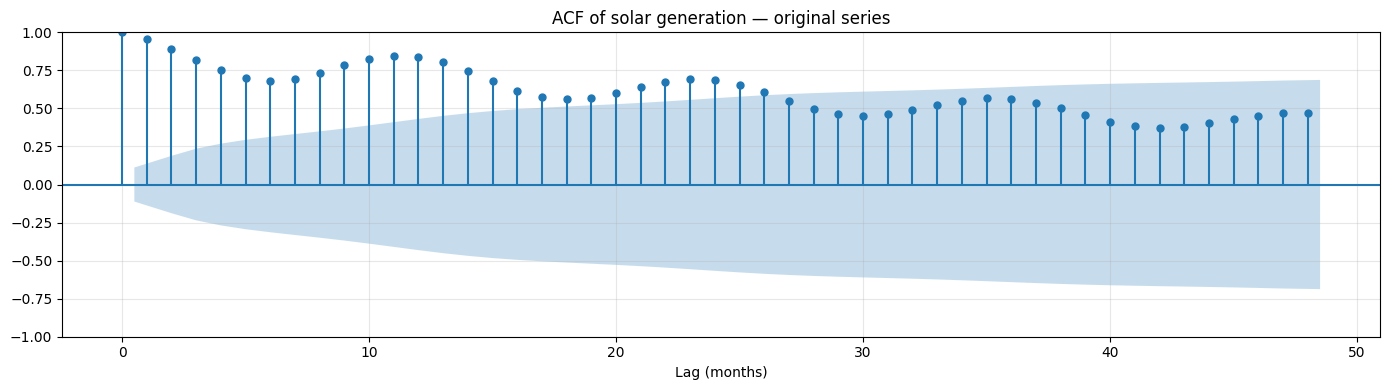

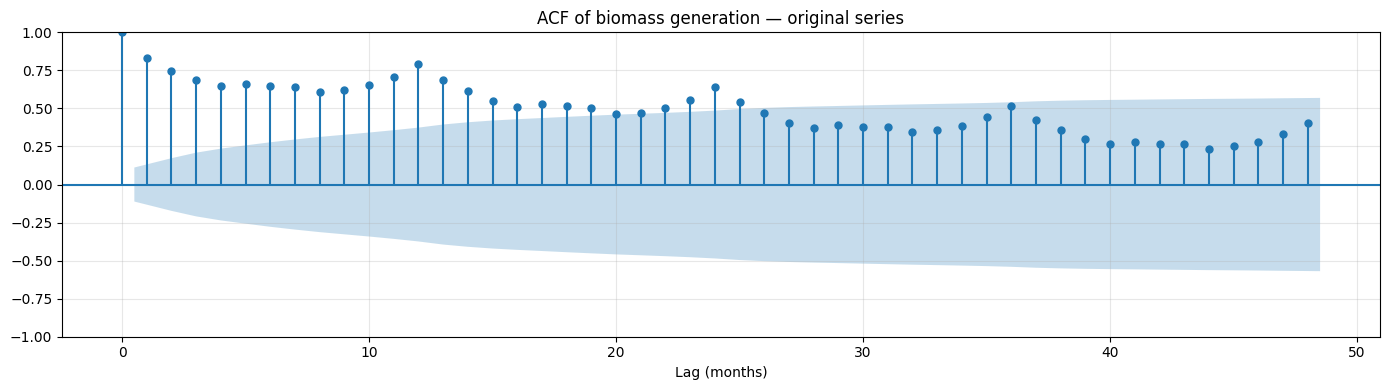

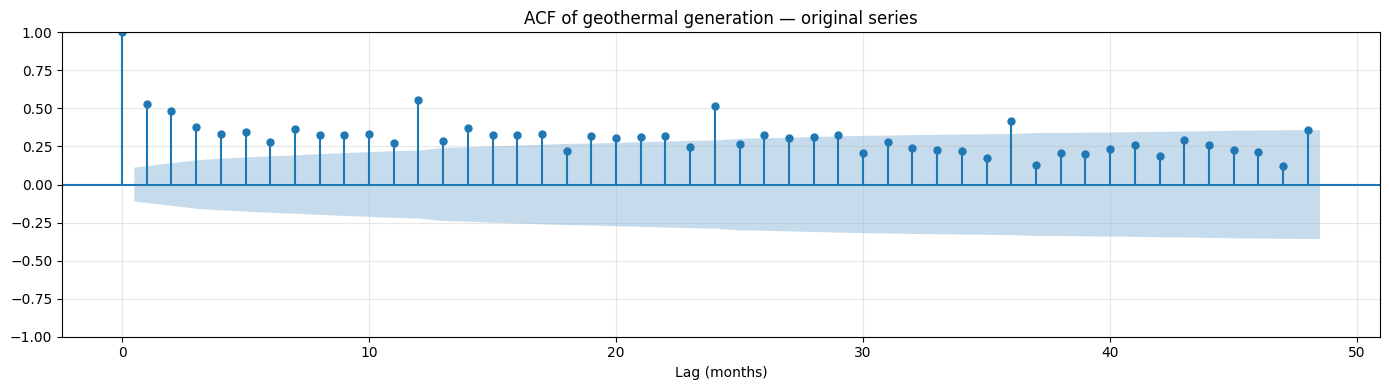

In [32]:
for r in RESOURCES:
    plt.figure(figsize=(14, 4))
    plot_acf(series[r], lags=48, ax=plt.gca())
    plt.title(f"ACF of {r} generation — original series")
    plt.xlabel("Lag (months)")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

In [33]:
from statsmodels.tsa.stattools import acf
for r in RESOURCES:
    a = acf(series[r], nlags=48)
    print(f"{r:10s}: ACF lag1 = {a[1]:.2f}, lag6 = {a[6]:.2f}, lag12 = {a[12]:.2f}, lag24 = {a[24]:.2f}, lag36 = {a[36]:.2f}, "
          f"first lag below 0.5 = {next((k for k in range(1, 49) if a[k] < 0.5), '>48')}")

hydro     : ACF lag1 = 0.75, lag6 = -0.20, lag12 = 0.64, lag24 = 0.55, lag36 = 0.50, first lag below 0.5 = 2
solar     : ACF lag1 = 0.96, lag6 = 0.68, lag12 = 0.84, lag24 = 0.69, lag36 = 0.56, first lag below 0.5 = 28
biomass   : ACF lag1 = 0.83, lag6 = 0.65, lag12 = 0.79, lag24 = 0.64, lag36 = 0.52, first lag below 0.5 = 20
geothermal: ACF lag1 = 0.53, lag6 = 0.28, lag12 = 0.56, lag24 = 0.52, lag36 = 0.42, first lag below 0.5 = 2


In [34]:
#@title Interpretation (generated from the results above)
rows_md, notes = [], []
for r in RESOURCES:
    a = acf(series[r], nlags=48)
    first_below = next((k for k in range(1, 49) if a[k] < 0.5), ">48")
    seasonal_peak = a[12] > max(a[11], a[13]) and a[12] > 0.1
    seasonal_bump = a[12] > a[6] + 0.05 and a[12] > 0.1          # lag 12 stands out against lag 6 even if a trend lifts the neighbours
    rows_md.append(f"| {r.capitalize()} | {a[1]:.2f} | {a[6]:.2f} | {a[12]:.2f} | {a[24]:.2f} | {a[36]:.2f} | {first_below} |")
    parts = []
    if a[1] >= 0.9: parts.append("a very high lag-1 value and slow decay, which signals a trend or a very persistent level")
    elif a[1] >= 0.7: parts.append("a high lag-1 value (strong month-to-month persistence)")
    else: parts.append("only moderate month-to-month persistence")
    if seasonal_peak and a[6] < 0: parts.append("a clear yearly cycle: peaks at lags 12, 24, 36 and negative values near lag 6")
    elif seasonal_peak: parts.append("a local peak at lag 12, which marks a yearly cycle")
    elif seasonal_bump: parts.append("lag 12 is higher than lag 6, a yearly cycle riding on top of the slow decay caused by the trend")
    else: parts.append("no clear spike at lag 12 (a weak or masked yearly cycle)")
    notes.append(f"* **{r.capitalize()}:** " + "; ".join(parts) + ".")
table = "\n".join(rows_md)
nl = "\n".join(notes)
show(f"""**ACF interpretation (original series)**

| Resource | Lag 1 | Lag 6 | Lag 12 | Lag 24 | Lag 36 | First lag < 0.5 |
|---|---|---|---|---|---|---|
{table}

{nl}

The original series are therefore not ready for ARIMA modelling: a slowly decaying ACF means a trend or a seasonal pattern is still present and has to be removed first.""")

**ACF interpretation (original series)**

| Resource | Lag 1 | Lag 6 | Lag 12 | Lag 24 | Lag 36 | First lag < 0.5 |
|---|---|---|---|---|---|---|
| Hydro | 0.75 | -0.20 | 0.64 | 0.55 | 0.50 | 2 |
| Solar | 0.96 | 0.68 | 0.84 | 0.69 | 0.56 | 28 |
| Biomass | 0.83 | 0.65 | 0.79 | 0.64 | 0.52 | 20 |
| Geothermal | 0.53 | 0.28 | 0.56 | 0.52 | 0.42 | 2 |

* **Hydro:** a high lag-1 value (strong month-to-month persistence); a clear yearly cycle: peaks at lags 12, 24, 36 and negative values near lag 6.
* **Solar:** a very high lag-1 value and slow decay, which signals a trend or a very persistent level; lag 12 is higher than lag 6, a yearly cycle riding on top of the slow decay caused by the trend.
* **Biomass:** a high lag-1 value (strong month-to-month persistence); a local peak at lag 12, which marks a yearly cycle.
* **Geothermal:** only moderate month-to-month persistence; a local peak at lag 12, which marks a yearly cycle.

The original series are therefore not ready for ARIMA modelling: a slowly decaying ACF means a trend or a seasonal pattern is still present and has to be removed first.

## 7. Stationarity Analysis

1. **ADF test**: H0 = the series has a unit root (non-stationary). p < 0.05 means stationary.
2. **KPSS test**: H0 = the series is stationary. p < 0.05 means non-stationary.

A series is called stationary only when **both** tests agree. The KPSS p-value is limited by its lookup table to the range 0.01–0.10.

In [35]:
alpha = 0.05

def stationarity_tests(x, name):
    x = x.dropna()
    adf_result = adfuller(x, regression="ct" if name.endswith("(original)") else "c")
    kpss_result = kpss(x, regression="ct" if name.endswith("(original)") else "c", nlags="auto")
    adf_ok = adf_result[1] < alpha
    kpss_ok = kpss_result[1] > alpha
    if adf_ok and kpss_ok:
        verdict = "Stationary"
    elif not adf_ok and not kpss_ok:
        verdict = "Non-stationary"
    else:
        verdict = "Mixed evidence"
    return {"series": name, "n": len(x), "ADF statistic": adf_result[0], "ADF p-value": adf_result[1],
            "KPSS statistic": kpss_result[0], "KPSS p-value": kpss_result[1], "Conclusion": verdict}

### 7.1 Original series (with constant + trend)

In [36]:
original_tests = pd.DataFrame([stationarity_tests(series[r], f"{r} (original)") for r in RESOURCES])
original_tests

,series,n,ADF statistic,ADF p-value,KPSS statistic,KPSS p-value,Conclusion
0,hydro (original),307,-4.189,0.005,0.142,0.058,Stationary
1,solar (original),307,0.011,0.994,0.662,0.010,Non-stationary
2,biomass (original),307,-0.067,0.993,0.638,0.010,Non-stationary
3,geothermal (original),307,-2.938,0.150,0.397,0.010,Non-stationary


In [37]:
# Detailed output for each series, in the same format as the ADF / KPSS printouts
for r in RESOURCES:
    adf_result = adfuller(series[r].dropna(), regression="ct")
    print(f"ADF TEST - {r.upper()} (ORIGINAL SERIES)")
    print("-" * 50)
    print(f"ADF Statistic : {adf_result[0]:.6f}")
    print(f"p-value       : {adf_result[1]:.10f}")
    print(f"Lags Used     : {adf_result[2]}")
    print(f"Observations  : {adf_result[3]}")
    print("Critical Values:", {k: round(v, 3) for k, v in adf_result[4].items()})
    print()

ADF TEST - HYDRO (ORIGINAL SERIES)
--------------------------------------------------
ADF Statistic : -4.188818
p-value       : 0.0046541970
Lags Used     : 14
Observations  : 292
Critical Values: {'1%': np.float64(-3.99), '5%': np.float64(-3.426), '10%': np.float64(-3.136)}

ADF TEST - SOLAR (ORIGINAL SERIES)
--------------------------------------------------
ADF Statistic : 0.010852
p-value       : 0.9943413514
Lags Used     : 15
Observations  : 291
Critical Values: {'1%': np.float64(-3.99), '5%': np.float64(-3.426), '10%': np.float64(-3.136)}

ADF TEST - BIOMASS (ORIGINAL SERIES)
--------------------------------------------------
ADF Statistic : -0.067392
p-value       : 0.9934831034
Lags Used     : 14
Observations  : 292
Critical Values: {'1%': np.float64(-3.99), '5%': np.float64(-3.426), '10%': np.float64(-3.136)}

ADF TEST - GEOTHERMAL (ORIGINAL SERIES)
--------------------------------------------------
ADF Statistic : -2.937690
p-value       : 0.1503426061
Lags Used     : 13
Obs

In [38]:
#@title Interpretation (generated from the results above)
rows_md, notes = [], []
for _, row in original_tests.iterrows():
    r = row["series"].split(" ")[0]
    adf_rej, kpss_rej = row["ADF p-value"] < alpha, row["KPSS p-value"] <= alpha
    rows_md.append(f"| {r.capitalize()} | {row['ADF p-value']:.4f} | {row['KPSS p-value']:.3f} | {row['Conclusion']} |")
    if row["Conclusion"] == "Stationary":
        notes.append(f"* **{r.capitalize()}:** ADF rejects a unit root and KPSS does not reject stationarity, so the series is stationary around a constant and a linear trend term.")
    elif row["Conclusion"] == "Non-stationary":
        notes.append(f"* **{r.capitalize()}:** ADF cannot reject a unit root and KPSS rejects stationarity, so both tests agree that the series is non-stationary.")
    elif adf_rej and kpss_rej:
        notes.append(f"* **{r.capitalize()}:** mixed evidence. ADF rejects a unit root, but KPSS rejects stationarity. This typically means the series has no unit root but still contains a persistent trend or a long-lasting change in level (here {trend_label(r).lower()}). It needs further transformation.")
    else:
        notes.append(f"* **{r.capitalize()}:** mixed evidence. Neither test gives a clear verdict (ADF does not reject a unit root, and KPSS does not reject stationarity), so the sample is not informative enough and the series is treated with care.")
table = "\n".join(rows_md)
nl = "\n".join(notes)
show(f"""**Stationarity of the original series** (tests with constant + trend; KPSS p-values are limited to 0.01–0.10)

| Resource | ADF p | KPSS p | Conclusion |
|---|---|---|---|
{table}

{nl}

Seasonality and trend affect these tests, so the next step is to transform each series and test again.""")

**Stationarity of the original series** (tests with constant + trend; KPSS p-values are limited to 0.01–0.10)

| Resource | ADF p | KPSS p | Conclusion |
|---|---|---|---|
| Hydro | 0.0047 | 0.058 | Stationary |
| Solar | 0.9943 | 0.010 | Non-stationary |
| Biomass | 0.9935 | 0.010 | Non-stationary |
| Geothermal | 0.1503 | 0.010 | Non-stationary |

* **Hydro:** ADF rejects a unit root and KPSS does not reject stationarity, so the series is stationary around a constant and a linear trend term.
* **Solar:** ADF cannot reject a unit root and KPSS rejects stationarity, so both tests agree that the series is non-stationary.
* **Biomass:** ADF cannot reject a unit root and KPSS rejects stationarity, so both tests agree that the series is non-stationary.
* **Geothermal:** ADF cannot reject a unit root and KPSS rejects stationarity, so both tests agree that the series is non-stationary.

Seasonality and trend affect these tests, so the next step is to transform each series and test again.

### 7.2 Making the series stationary
We test the decomposition residual (trend and seasonality removed), the first difference (Δ), the seasonal difference (Δ12) and both together.
Solar is first log-transformed, because its seasonality is multiplicative.

In [39]:
transformed = {
    "hydro":      series["hydro"],
    "solar":      np.log(series["solar"]),     # log makes the growing seasonal swings constant
    "biomass":    series["biomass"],
    "geothermal": series["geothermal"],
}

rows = []
for r in RESOURCES:
    z = transformed[r]
    resid = decomposition[r].resid
    if decomp_model[r] == "multiplicative":
        resid = np.log(resid)
    rows.append(stationarity_tests(z, f"{r}: level, constant only (no trend term)"))
    rows.append(stationarity_tests(resid, f"{r}: decomposition residual"))
    rows.append(stationarity_tests(z.diff(), f"{r}: first difference (d=1)"))
    rows.append(stationarity_tests(z.diff(12), f"{r}: seasonal difference (D=1)"))
    rows.append(stationarity_tests(z.diff(12).diff(), f"{r}: both (d=1, D=1)"))
transformed_tests = pd.DataFrame(rows)
transformed_tests

,series,n,ADF statistic,ADF p-value,KPSS statistic,KPSS p-value,Conclusion
0,"hydro: level, constant only (no trend term)",307,-3.705,0.004,0.326,0.100,Stationary
1,hydro: decomposition residual,295,-8.828,0.000,0.013,0.100,Stationary
2,hydro: first difference (d=1),306,-5.770,0.000,0.050,0.100,Stationary
3,hydro: seasonal difference (D=1),295,-4.372,0.000,0.085,0.100,Stationary
4,"hydro: both (d=1, D=1)",294,-7.915,0.000,0.042,0.100,Stationary
5,"solar: level, constant only (no trend term)",307,-0.553,0.881,2.809,0.010,Non-stationary
6,solar: decomposition residual,295,-1.520,0.524,1.514,0.010,Non-stationary
7,solar: first difference (d=1),306,-2.873,0.049,0.012,0.100,Stationary
8,solar: seasonal difference (D=1),295,-2.292,0.174,0.368,0.091,Mixed evidence
9,"solar: both (d=1, D=1)",294,-6.379,0.000,0.123,0.100,Stationary


### 7.3 Choosing the differencing orders (d, D)
The rule is applied in the same way for every resource (and again automatically on the training data in Review 2):

1. If the level (constant only) is already stationary by **both** tests, no differencing is used (d = 0, D = 0).
2. Otherwise, use a seasonal difference (D = 1) when the seasonal strength is above 0.64.
3. Then add a first difference (d = 1) if ADF and KPSS still do not agree on stationarity.

In [40]:
def choose_differencing(z):
    level_ok = adfuller(z)[1] < alpha and kpss(z, regression="c", nlags="auto")[1] > alpha
    parts = seasonal_decompose(z, model="additive", period=12)
    resid, seas = parts.resid.dropna(), parts.seasonal[parts.resid.notna()]
    seasonal_strength = max(0, 1 - resid.var() / (seas + resid).var())
    if level_ok:
        return 0, 0, seasonal_strength, True, np.nan, np.nan
    D = 1 if seasonal_strength > 0.64 else 0
    x = z.diff(12).dropna() if D else z
    adf_p = adfuller(x)[1]
    kpss_p = kpss(x, regression="c", nlags="auto")[1]
    d = 0 if (adf_p < alpha and kpss_p > alpha) else 1
    return d, D, seasonal_strength, False, adf_p, kpss_p

rows, DIFF_CHOICE = [], {}
for r in RESOURCES:
    d, D, fs, level_ok, adf_p, kpss_p = choose_differencing(transformed[r])
    DIFF_CHOICE[r] = (d, D)
    rows.append({"resource": r, "level stationary?": level_ok, "seasonal_strength (additive, model scale)": fs,
                 "D": D, "ADF p (after D)": adf_p, "KPSS p (after D)": kpss_p, "d": d})
pd.DataFrame(rows).set_index("resource")

,level stationary?,"seasonal_strength (additive, model scale)",D,ADF p (after D),KPSS p (after D),d
resource,,,,,,
hydro,True,0.740,0,NaN,NaN,0
solar,False,0.715,1,0.174,0.091,1
biomass,False,0.676,1,0.076,0.010,1
geothermal,False,0.387,0,0.142,0.010,1


In [41]:
#@title Interpretation (generated from the results above)
info = {r: choose_differencing(transformed[r]) for r in RESOURCES}
def final_key(r):
    d, D = DIFF_CHOICE[r]
    return {(0, 0): "level, constant only (no trend term)", (0, 1): "seasonal difference (D=1)", (1, 0): "first difference (d=1)", (1, 1): "both (d=1, D=1)"}[(d, D)]
rows_md, notes = [], []
for r in RESOURCES:
    d, D, ss, level_ok, adf_p_after, kpss_p_after = info[r]
    row = transformed_tests[transformed_tests["series"] == f"{r}: {final_key(r)}"].iloc[0]
    tf = "log" if r == "solar" else "none"
    rows_md.append(f"| {r.capitalize()} | {tf} | {'yes' if level_ok else 'no'} | {ss:.2f} | {d} | {D} | {row['ADF p-value']:.4f} | {row['KPSS p-value']:.3f} | {row['Conclusion']} |")
    if level_ok:
        notes.append(f"* **{r.capitalize()}:** the level is already stationary by both tests (constant only), so **no differencing** is used (d = 0, D = 0). Differencing would only add noise.")
    else:
        why = (f"The seasonal strength is {ss:.2f}, which is {'above' if D else 'not above'} 0.64, so " + ("a seasonal difference (D = 1) is applied" if D else "no seasonal difference is used"))
        stage = "after the seasonal difference" if D else "on the level"
        why2 = (f"; the series is then stationary ({stage}: ADF p = {adf_p_after:.4f}, KPSS p = {kpss_p_after:.3f}) and no further difference is needed (d = 0)." if d == 0 else
                f"; {stage} ADF p = {adf_p_after:.4f} and KPSS p = {kpss_p_after:.3f} still do not both indicate stationarity, so a first difference (d = 1) is added.")
        notes.append(f"* **{r.capitalize()}:** the level is not stationary by both tests. {why}{why2}")
    if row["Conclusion"] != "Stationary":
        notes.append(f"  * Warning: after this transformation the tests still give **{row['Conclusion'].lower()}** (ADF p = {row['ADF p-value']:.4f}, KPSS p = {row['KPSS p-value']:.3f}); treat the series with care.")
table = "\n".join(rows_md)
nl = "\n".join(notes)
show(f"""**Stationarity analysis: final interpretation**

| Resource | Transform | Level stationary? | Seasonal strength | d | D | ADF p (final) | KPSS p (final) | Result |
|---|---|---|---|---|---|---|---|---|
{table}

{nl}

The same rule is applied again to the training data only in Review 2, so that the test period is never used to choose the differencing.""")

**Stationarity analysis: final interpretation**

| Resource | Transform | Level stationary? | Seasonal strength | d | D | ADF p (final) | KPSS p (final) | Result |
|---|---|---|---|---|---|---|---|---|
| Hydro | none | yes | 0.74 | 0 | 0 | 0.0040 | 0.100 | Stationary |
| Solar | log | no | 0.71 | 1 | 1 | 0.0000 | 0.100 | Stationary |
| Biomass | none | no | 0.68 | 1 | 1 | 0.0000 | 0.100 | Stationary |
| Geothermal | none | no | 0.39 | 1 | 0 | 0.0000 | 0.100 | Stationary |

* **Hydro:** the level is already stationary by both tests (constant only), so **no differencing** is used (d = 0, D = 0). Differencing would only add noise.
* **Solar:** the level is not stationary by both tests. The seasonal strength is 0.71, which is above 0.64, so a seasonal difference (D = 1) is applied; after the seasonal difference ADF p = 0.1745 and KPSS p = 0.091 still do not both indicate stationarity, so a first difference (d = 1) is added.
* **Biomass:** the level is not stationary by both tests. The seasonal strength is 0.68, which is above 0.64, so a seasonal difference (D = 1) is applied; after the seasonal difference ADF p = 0.0761 and KPSS p = 0.010 still do not both indicate stationarity, so a first difference (d = 1) is added.
* **Geothermal:** the level is not stationary by both tests. The seasonal strength is 0.39, which is not above 0.64, so no seasonal difference is used; on the level ADF p = 0.1422 and KPSS p = 0.010 still do not both indicate stationarity, so a first difference (d = 1) is added.

The same rule is applied again to the training data only in Review 2, so that the test period is never used to choose the differencing.

## 8. ACF / PACF Analysis of the Stationary Series
The ACF and PACF are examined on the differenced series selected above. This is the series an ARIMA/SARIMA model works with.

{'hydro': 'hydro (level)', 'solar': 'Δ Δ12 log(solar)', 'biomass': 'Δ Δ12 biomass', 'geothermal': 'Δ geothermal'}


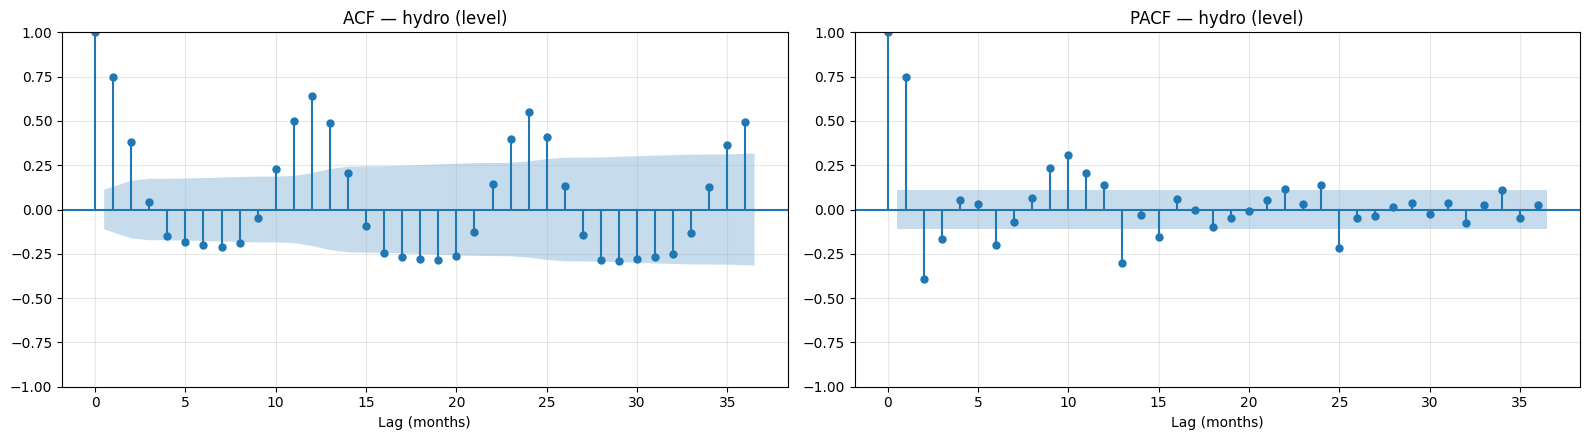

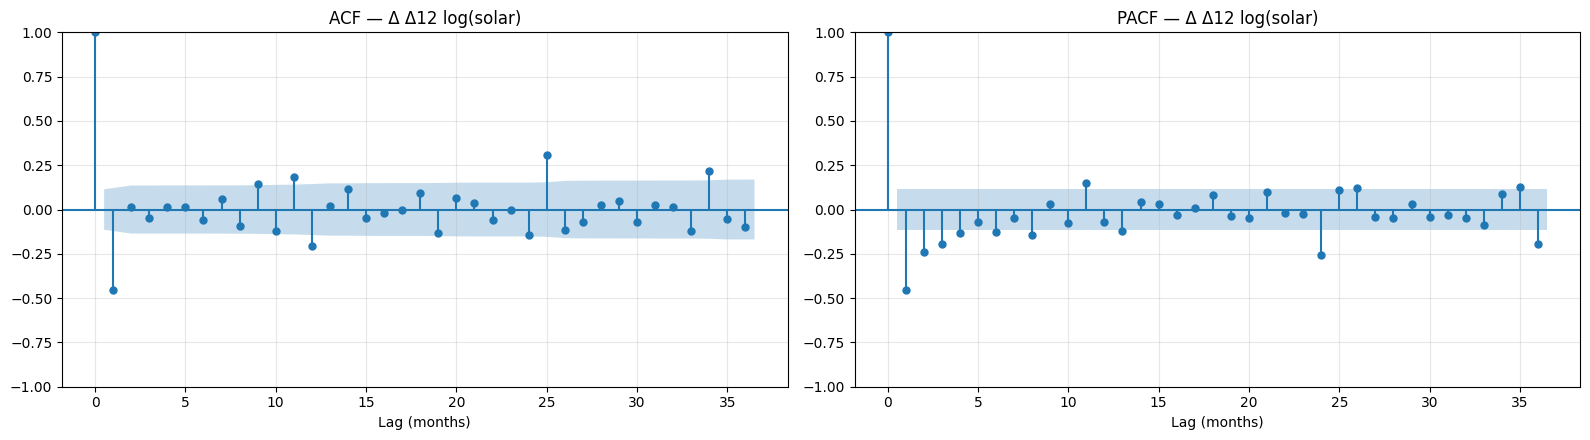

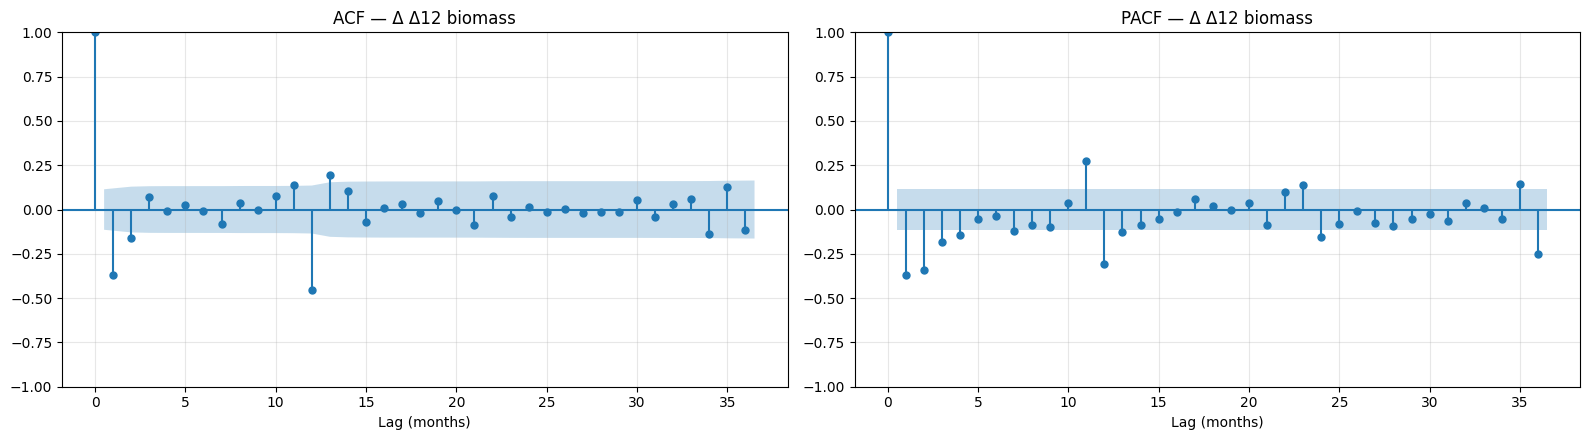

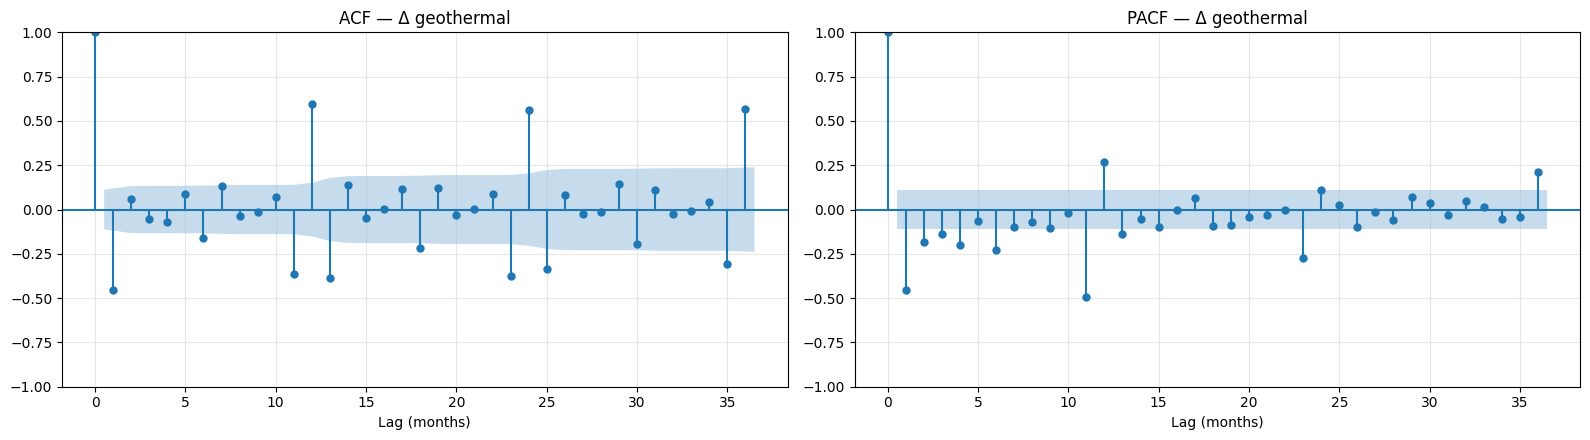

In [42]:
# Build the stationary series from the (d, D) chosen above
def make_stationary(z, d, D):
    out = z
    if D:
        out = out.diff(12)
    for _ in range(d):
        out = out.diff()
    return out.dropna()

stationary = {r: make_stationary(transformed[r], *DIFF_CHOICE[r]) for r in RESOURCES}

def label(r):
    d, D = DIFF_CHOICE[r]
    base = f"log({r})" if r == "solar" else r
    prefix = ("Δ " if d else "") + ("Δ12 " if D else "")
    return f"{prefix}{base}" if (d or D) else f"{r} (level)"
stationary_label = {r: label(r) for r in RESOURCES}
print(stationary_label)

for r in RESOURCES:
    fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
    plot_acf(stationary[r], lags=36, ax=axes[0])
    plot_pacf(stationary[r], lags=36, method="ywm", ax=axes[1])
    axes[0].set_title(f"ACF — {stationary_label[r]}")
    axes[1].set_title(f"PACF — {stationary_label[r]}")
    for ax in axes:
        ax.set_xlabel("Lag (months)")
        ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

In [43]:
from statsmodels.tsa.stattools import pacf

acf_rows = []
for r in RESOURCES:
    x = stationary[r]
    bound = 1.96 / np.sqrt(len(x))
    a = acf(x, nlags=36)
    p = pacf(x, nlags=36, method="ywm")
    acf_rows.append({
        "resource": r,
        "series": stationary_label[r],
        "ACF lag 1": a[1], "ACF lag 12": a[12], "PACF lag 1": p[1], "PACF lag 12": p[12],
        "significant ACF lags (≤13)": [k for k in range(1, 14) if abs(a[k]) > bound],
        "significant PACF lags (≤13)": [k for k in range(1, 14) if abs(p[k]) > bound],
        "95% bound": bound,
    })
acf_summary = pd.DataFrame(acf_rows).set_index("resource")
acf_summary

,series,ACF lag 1,ACF lag 12,PACF lag 1,PACF lag 12,significant ACF lags (≤13),significant PACF lags (≤13),95% bound
resource,,,,,,,,
hydro,hydro (level),0.745,0.643,0.745,0.138,"[1, 2, 4, 5, 6, 7, 8, 10, 11, 12, 13]","[1, 2, 3, 6, 9, 10, 11, 12, 13]",0.112
solar,Δ Δ12 log(solar),-0.452,-0.206,-0.452,-0.070,"[1, 9, 10, 11, 12]","[1, 2, 3, 4, 6, 8, 11, 13]",0.114
biomass,Δ Δ12 biomass,-0.371,-0.453,-0.371,-0.307,"[1, 2, 11, 12, 13]","[1, 2, 3, 4, 7, 11, 12, 13]",0.114
geothermal,Δ geothermal,-0.452,0.597,-0.452,0.267,"[1, 6, 7, 11, 12, 13]","[1, 2, 3, 4, 6, 11, 12, 13]",0.112


In [44]:
#@title Interpretation (generated from the results above)
def suggest(r):
    d, D = DIFF_CHOICE[r]
    row = acf_summary.loc[r]
    sa, sp = list(row["significant ACF lags (≤13)"]), list(row["significant PACF lags (≤13)"])
    p = q = P = Q = 0
    lag1_sig = (1 in sa) or (1 in sp)
    ac_cut = not any(k in sa for k in (2, 3))          # ACF cuts off after lag 1
    pc_cut = not any(k in sp for k in (2, 3))          # PACF cuts off after lag 1
    if lag1_sig:
        if ac_cut and not pc_cut: q = 1                 # MA(1) signature
        elif pc_cut and not ac_cut: p = 1               # AR(1) signature
        elif ac_cut and pc_cut: q = 1                   # AR(1) or MA(1) are indistinguishable; MA(1) is used as the starting point
        else: p, q = 1, 1                               # no clean cut-off in either: mixed ARMA(1,1)
    if 12 in sa and row["ACF lag 12"] > 0: P = 1
    if (12 in sa and row["ACF lag 12"] < 0) or (12 in sp and row["PACF lag 12"] < 0): Q = 1
    const = " with a constant" if (d == 0 and D == 0) else ""
    return f"SARIMA({p},{d},{q})({P},{D},{Q})12{const}"
rows_md = []
for r in RESOURCES:
    row = acf_summary.loc[r]
    rows_md.append(f"| {stationary_label[r]} | lag 1 = {row['ACF lag 1']:.2f}; lag 12 = {row['ACF lag 12']:.2f}; significant lags {list(row['significant ACF lags (≤13)'])} "
                   f"| lag 1 = {row['PACF lag 1']:.2f}; lag 12 = {row['PACF lag 12']:.2f}; significant lags {list(row['significant PACF lags (≤13)'])} | {suggest(r)} |")
table = "\n".join(rows_md)
bound = acf_summary["95% bound"].round(3).to_dict()
show(f"""**ACF / PACF interpretation and suggested starting models**

| Stationary series | ACF | PACF | Starting model suggested by the pattern |
|---|---|---|---|
{table}

* Significance is judged against the 95% bound ±1.96/√n (hydro {bound['hydro']}, solar {bound['solar']}, biomass {bound['biomass']}, geothermal {bound['geothermal']}).
* The suggestions follow the usual reading rules: a cut-off in the ACF indicates an MA term, a cut-off in the PACF indicates an AR term, and a spike at lag 12 indicates a seasonal MA (negative ACF) or seasonal AR (positive ACF) term.
* These are **starting points, not final models**. Review 2 searches over small SARIMA models using AIC on the training data and compares them with other model families on the test data.""")

**ACF / PACF interpretation and suggested starting models**

| Stationary series | ACF | PACF | Starting model suggested by the pattern |
|---|---|---|---|
| hydro (level) | lag 1 = 0.75; lag 12 = 0.64; significant lags [1, 2, 4, 5, 6, 7, 8, 10, 11, 12, 13] | lag 1 = 0.75; lag 12 = 0.14; significant lags [1, 2, 3, 6, 9, 10, 11, 12, 13] | SARIMA(1,0,1)(1,0,0)12 with a constant |
| Δ Δ12 log(solar) | lag 1 = -0.45; lag 12 = -0.21; significant lags [1, 9, 10, 11, 12] | lag 1 = -0.45; lag 12 = -0.07; significant lags [1, 2, 3, 4, 6, 8, 11, 13] | SARIMA(0,1,1)(0,1,1)12 |
| Δ Δ12 biomass | lag 1 = -0.37; lag 12 = -0.45; significant lags [1, 2, 11, 12, 13] | lag 1 = -0.37; lag 12 = -0.31; significant lags [1, 2, 3, 4, 7, 11, 12, 13] | SARIMA(1,1,1)(0,1,1)12 |
| Δ geothermal | lag 1 = -0.45; lag 12 = 0.60; significant lags [1, 6, 7, 11, 12, 13] | lag 1 = -0.45; lag 12 = 0.27; significant lags [1, 2, 3, 4, 6, 11, 12, 13] | SARIMA(0,1,1)(1,0,0)12 |

* Significance is judged against the 95% bound ±1.96/√n (hydro 0.112, solar 0.114, biomass 0.114, geothermal 0.112).
* The suggestions follow the usual reading rules: a cut-off in the ACF indicates an MA term, a cut-off in the PACF indicates an AR term, and a spike at lag 12 indicates a seasonal MA (negative ACF) or seasonal AR (positive ACF) term.
* These are **starting points, not final models**. Review 2 searches over small SARIMA models using AIC on the training data and compares them with other model families on the test data.

## 9. Initial Findings and Research Hypotheses

In [45]:
#@title Interpretation (generated from the results above)
sidx = seasonal_index
def pk(r): return MONTH_NAME[int(sidx[r].idxmax())]
def tr_(r): return MONTH_NAME[int(sidx[r].idxmin())]
def amp(r): return (sidx[r].max() - 1) * 100
T = trend_summary
dc = {r: f"d={DIFF_CHOICE[r][0]}, D={DIFF_CHOICE[r][1]}" for r in RESOURCES}
s_order = list(strength["seasonal_strength"].sort_values(ascending=False).index)
gap = abs(int(sidx["hydro"].idxmax()) - int(sidx["solar"].idxmax())); gap = min(gap, 12 - gap)
if gap <= 2:
    hs_sentence = f"Hydro and solar peak in neighbouring months ({pk('hydro')} and {pk('solar')}), so they do not offset each other seasonally."
else:
    hs_sentence = f"Hydro and solar peak in different seasons ({pk('hydro')} and {pk('solar')}), so they partly offset each other during the year."
show(f"""### Initial findings

1. **Hydro** ({annual.loc[2025, 'hydro']:,.0f} GWh in 2025) has **{trend_label('hydro').lower()}**. Annual output ranges from {annual['hydro'].min():,.0f} to {annual['hydro'].max():,.0f} GWh, driven by wet and dry years. It peaks in {pk('hydro')} ({amp('hydro'):+.0f}%) and is lowest in {tr_('hydro')} ({(sidx['hydro'].min() - 1) * 100:+.0f}%).
2. **Solar** grew from {annual.loc[2001, 'solar']:,.0f} GWh (2001) to {annual.loc[2025, 'solar']:,.0f} GWh (2025), about {T.loc['solar', 'CAGR_%']:.0f}% per year ({T.loc['solar', 'CAGR_last_5y_%']:.0f}% per year over the last five years). It has a strong multiplicative cycle, with a peak in {pk('solar')} ({amp('solar'):+.0f}%) and a low in {tr_('solar')} ({(sidx['solar'].min() - 1) * 100:+.0f}%), and is modelled on the log scale.
3. **Biomass** peaked in {int(T.loc['biomass', 'peak_year'])} ({T.loc['biomass', 'peak_year_GWh']:,.0f} GWh) and has since fallen to {annual.loc[2025, 'biomass']:,.0f} GWh in 2025. Its seasonal cycle is small (peak {pk('biomass')}, {amp('biomass'):+.0f}%).
4. **Geothermal** is the steadiest resource: {trend_label('geothermal').lower()} ({T.loc['geothermal', 'CAGR_%']:.1f}%/yr), with a very small seasonal cycle (peak {pk('geothermal')}, {amp('geothermal'):+.0f}%) and an isolated dip in {g_dip:%b %Y} that does not repeat.
5. {hs_sentence}
6. Differencing choices from the stationarity tests: hydro ({dc['hydro']}), solar on the log scale ({dc['solar']}), biomass ({dc['biomass']}), geothermal ({dc['geothermal']}). The ACF/PACF patterns suggest {suggest('hydro')} for hydro, {suggest('solar')} for log-solar, {suggest('biomass')} for biomass and {suggest('geothermal')} for geothermal as starting points.

### Research hypotheses (tested in Review 2)

* **H1:** All four resources show a 12-month seasonal cycle, but with different strength and peak months (seasonal strength is highest for {s_order[0]} and lowest for {s_order[-1]}).
* **H2:** Seasonal models (SARIMA, Holt-Winters, seasonal ML) forecast more accurately than the seasonal-naive baseline for each resource.
* **H3:** Solar requires a model that captures exponential growth. Models without a trend (seasonal naive) will under-forecast it, and the log transform with differencing will help.
* **H4:** Geothermal and biomass are low-variance series, so simple models can match complex ones. Hydro stays the hardest to forecast because it depends on weather that is not in the data.""")

### Initial findings

1. **Hydro** (154,215 GWh in 2025) has **no meaningful trend (year-to-year swings)**. Annual output ranges from 137,460 to 220,225 GWh, driven by wet and dry years. It peaks in May (+29%) and is lowest in Oct (-27%).
2. **Solar** grew from 543 GWh (2001) to 108,827 GWh (2025), about 25% per year (17% per year over the last five years). It has a strong multiplicative cycle, with a peak in Jun (+54%) and a low in Dec (-58%), and is modelled on the log scale.
3. **Biomass** peaked in 2014 (11,332 GWh) and has since fallen to 7,578 GWh in 2025. Its seasonal cycle is small (peak Aug, +8%).
4. **Geothermal** is the steadiest resource: slow upward drift that has levelled off (0.5%/yr), with a very small seasonal cycle (peak Dec, +5%) and an isolated dip in Nov 2019 that does not repeat.
5. Hydro and solar peak in neighbouring months (May and Jun), so they do not offset each other seasonally.
6. Differencing choices from the stationarity tests: hydro (d=0, D=0), solar on the log scale (d=1, D=1), biomass (d=1, D=1), geothermal (d=1, D=0). The ACF/PACF patterns suggest SARIMA(1,0,1)(1,0,0)12 with a constant for hydro, SARIMA(0,1,1)(0,1,1)12 for log-solar, SARIMA(1,1,1)(0,1,1)12 for biomass and SARIMA(0,1,1)(1,0,0)12 for geothermal as starting points.

### Research hypotheses (tested in Review 2)

* **H1:** All four resources show a 12-month seasonal cycle, but with different strength and peak months (seasonal strength is highest for hydro and lowest for geothermal).
* **H2:** Seasonal models (SARIMA, Holt-Winters, seasonal ML) forecast more accurately than the seasonal-naive baseline for each resource.
* **H3:** Solar requires a model that captures exponential growth. Models without a trend (seasonal naive) will under-forecast it, and the log transform with differencing will help.
* **H4:** Geothermal and biomass are low-variance series, so simple models can match complex ones. Hydro stays the hardest to forecast because it depends on weather that is not in the data.